[LOAD] AP: grid 2202×3010, dx=30.0 m
[OUTLETS] coastline outlets: 118379
[SELECT] Using ALL coastline outlets: 118379 (no filtering)
[BASINS] using 118379 basins for θ optimization
[OPT] coarse sweep …
[OPT] coarse done in 1100.0s
[OPT] refine around θ=0.525 → [0.465, 0.585] …
[OPT] refine done in 4205.4s

[RESULT] θ*_coarse=0.525  SSR=7.918e+07
[RESULT] θ*_refine=0.537  SSR=7.903e+07


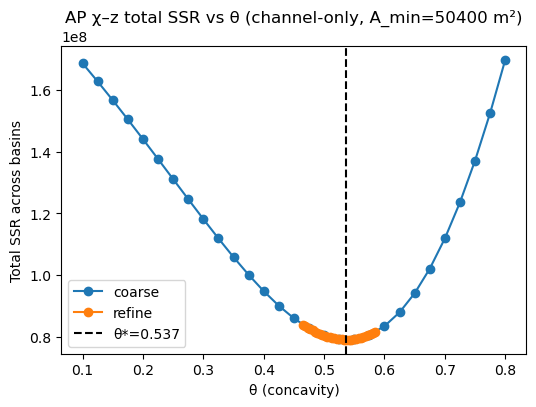


[QUALITY @ θ*=0.537]
  ks median=47.1781
  RMSE (m): median=4.32  IQR=(1.68, 8.86)  min/max=(0.00, 32.78)  n=1820
  R²₀:      median=0.974  IQR=(0.954, 0.987)  min/max=(0.000, 1.000)  n=1820
  nRMSE:    median=0.100  IQR=(0.067, 0.143)
  Global RMS per point ≈ 13.19 m


In [4]:
# ===============================================
# χ-based concavity optimization (final settings)
# Channel-only χ (stream_A_min = A_MIN), no caps
# With option to bypass outlet filtering and use ALL outlets
# ===============================================
import numpy as np, math, time
import matplotlib.pyplot as plt
from TopoAnalysis import dem as d

# -----------------------
# 0) Dataset registry
# -----------------------
DATA = {
    "AP": dict(
        elev="data/taylors_original_dataset/AP_filled",
        area="data/taylors_original_dataset/AP_area",
        flow="data/taylors_original_dataset/AP_fd",
        A_MIN=5.04e4,  # Taylor's AP channel threshold (m^2)
    ),
    "GM": dict(
        elev="data/taylors_original_dataset/GM_10mS_filled",  # or GM_10mN_filled / combined
        area="data/taylors_original_dataset/GM_10mS_area",
        flow="data/taylors_original_dataset/GM_10mS_fd",
        A_MIN=1.0e4,   # Taylor's GM channel threshold (m^2)
    ),

# -----------------------
# 1) Choose dataset + knobs
# -----------------------
tag = "AP"  # <-- change to "GM" as needed
USE_ALL_OUTLETS = True   # <-- set True to bypass filtering and use ALL coastline outlets
N_BASINS = None          # optional cap (e.g., 1000); None = use all selected

cfg = DATA[tag]
A_MIN = cfg["A_MIN"]

# -----------------------
# 2) Load grids
# -----------------------
elev = d.Elevation.load(cfg["elev"])
area = d.Area.load(cfg["area"])
fd   = d.FlowDirectionD8.load(cfg["flow"])

Z, A = elev._griddata, area._griddata
ny, nx = Z.shape
dx = elev._georef_info.dx

assert np.isfinite(Z).any(), "Elevation grid has no finite values."
assert np.isfinite(A).any() and (np.nanmax(A) > 0), "Area grid invalid."
print(f"[LOAD] {tag}: grid {ny}×{nx}, dx={dx} m")

# -----------------------
# 3) Coastline outlets → (optionally) filter
# -----------------------
outlets_xy = elev.outlets_at_coastlines()
rc_all = elev._xy_to_rowscols(list(outlets_xy))
print(f"[OUTLETS] coastline outlets: {len(rc_all)}")

def upstream_deg(i, j):
    c = 0
    for (ui, uj) in fd.get_upstream_cell_indexes(i, j):
        if ui is None or uj is None: 
            continue
        if 0 <= ui < ny and 0 <= uj < nx and np.isfinite(Z[ui, uj]):
            c += 1
    return c

if USE_ALL_OUTLETS:
    # Use ALL outlets; attach area if finite (NaN otherwise). No filtering here.
    chosen_all = []
    for (i, j) in rc_all:
        aij = A[i, j] if (0 <= i < ny and 0 <= j < nx) else np.nan
        chosen_all.append((i, j, float(aij) if np.isfinite(aij) else np.nan))
    print(f"[SELECT] Using ALL coastline outlets: {len(chosen_all)} (no filtering)")
    chosen = chosen_all
else:
    # Original “good outlet” filter
    good_rc, nan_elev, small_area, no_up = [], 0, 0, 0
    for (i, j) in rc_all:
        if not (0 <= i < ny and 0 <= j < nx): 
            continue
        if not np.isfinite(Z[i, j]): 
            nan_elev += 1; 
            continue
        if not (np.isfinite(A[i, j]) and A[i, j] >= A_MIN):
            small_area += 1; 
            continue
        if upstream_deg(i, j) <= 0:
            no_up += 1
            continue
        good_rc.append((i, j, float(A[i, j])))
    good_rc.sort(key=lambda t: (np.nan_to_num(t[2], nan=-1.0)), reverse=True)
    print(f"[FILTER] kept={len(good_rc)} | rejected (nan_elev={nan_elev}, small_area={small_area}, no_up={no_up})")
    chosen = good_rc

# Optional cap
if (N_BASINS is not None) and (len(chosen) > N_BASINS):
    idxs = np.linspace(0, len(chosen)-1, N_BASINS).astype(int)
    chosen = [chosen[i] for i in idxs]
print(f"[BASINS] using {len(chosen)} basins for θ optimization")

# -----------------------
# 4) χ traversal (channel-only, no caps)
# -----------------------
def chi_traverse(theta, root_ij, A, Z, fd, dx, stream_A_min):
    """
    Compute (chi, z - z0) for one basin by upstream D8 walk.
    Channel-only: require A >= stream_A_min.
    No visit/time caps.
    """
    (ri, rj) = root_ij
    if not (0 <= ri < ny and 0 <= rj < nx) or not np.isfinite(Z[ri, rj]):
        return np.empty(0), np.empty(0)

    def Apow(i, j):
        a = A[i, j]
        return (a ** (-theta)) if (a > 0 and np.isfinite(a)) else np.nan

    def seg_len(pi, pj, ui, uj):
        return dx * (math.sqrt(2.0) if (abs(ui - pi) == 1 and abs(uj - pj) == 1) else 1.0)

    z0 = Z[ri, rj]
    chi_vals, z_vals = [0.0], [0.0]
    visited = np.zeros_like(Z, dtype=bool)
    visited[ri, rj] = True
    stack = [((ri, rj), 0.0)]

    while stack:
        (pi, pj), parent_chi = stack.pop()
        for (ui, uj) in fd.get_upstream_cell_indexes(pi, pj):
            if ui is None or uj is None: 
                continue
            if ui < 0 or uj < 0 or ui >= ny or uj >= nx:
                continue
            if visited[ui, uj]: 
                continue
            if not np.isfinite(Z[ui, uj]): 
                continue
            if not (np.isfinite(A[ui, uj]) and A[ui, uj] >= stream_A_min):
                continue

            a1, a2 = Apow(pi, pj), Apow(ui, uj)
            next_chi = parent_chi
            if np.isfinite(a1) and np.isfinite(a2):
                next_chi = parent_chi + 0.5 * (a1 + a2) * seg_len(pi, pj, ui, uj)

            chi_vals.append(next_chi)
            z_vals.append(Z[ui, uj] - z0)
            visited[ui, uj] = True
            stack.append(((ui, uj), next_chi))

    x = np.asarray(chi_vals, float); y = np.asarray(z_vals, float)
    m = np.isfinite(x) & np.isfinite(y) & (x > 0.0)
    return x[m], y[m]

def ols_origin(x, y):
    if x.size < 3:
        return np.nan, np.nan
    den = float(np.dot(x, x))
    if den <= 0 or not np.isfinite(den):
        return np.nan, np.nan
    k = float(np.dot(x, y) / den)
    r = y - k * x
    return k, float(np.dot(r, r))

# -----------------------
# 5) θ optimization (coarse→refine) on total SSR across basins
# -----------------------
def total_ssr_for_theta(theta, outlets):
    total = 0.0
    for (i0, j0, _a0) in outlets:
        x, y = chi_traverse(theta, (i0, j0), A, Z, fd, dx, stream_A_min=A_MIN)
        _k, ssr = ols_origin(x, y)
        if np.isfinite(ssr):
            total += ssr
    return total

print("[OPT] coarse sweep …")
coarse_thetas = np.linspace(0.10, 0.80, 29)
coarse = []
t0 = time.time()
for th in coarse_thetas:
    coarse.append((th, total_ssr_for_theta(th, chosen)))
print(f"[OPT] coarse done in {time.time()-t0:.1f}s")

best_th_coarse, best_ssr_coarse = min(coarse, key=lambda kv: kv[1])
lo = max(0.10, best_th_coarse - 0.06)
hi = min(0.80, best_th_coarse + 0.06)

print(f"[OPT] refine around θ={best_th_coarse:.3f} → [{lo:.3f}, {hi:.3f}] …")
refine_thetas = np.linspace(lo, hi, 31)
refine = []
t1 = time.time()
for th in refine_thetas:
    refine.append((th, total_ssr_for_theta(th, chosen)))
print(f"[OPT] refine done in {time.time()-t1:.1f}s")

best_th_refine, best_ssr_refine = min(refine, key=lambda kv: kv[1])
theta_star = best_th_refine
print(f"\n[RESULT] θ*_coarse={best_th_coarse:.3f}  SSR={best_ssr_coarse:.3e}")
print(f"[RESULT] θ*_refine={best_th_refine:.3f}  SSR={best_ssr_refine:.3e}")

plt.figure(figsize=(6,4))
plt.plot([t for t,_ in coarse], [s for _,s in coarse], 'o-', label='coarse')
plt.plot([t for t,_ in refine], [s for _,s in refine], 'o-', label='refine')
plt.axvline(best_th_refine, color='k', ls='--', label=f'θ*={best_th_refine:.3f}')
plt.xlabel("θ (concavity)"); plt.ylabel("Total SSR across basins")
plt.title(f"{tag} χ–z total SSR vs θ (channel-only, A_min={A_MIN:.0f} m²)")
plt.legend(); plt.show()

# -----------------------
# 6) Fit-quality diagnostics at θ*
# -----------------------
def r2_through_origin(y, yhat):
    ssr = float(np.dot((y - yhat), (y - yhat)))
    denom = float(np.dot(y, y))
    if denom <= 0 or not np.isfinite(denom):
        return np.nan, ssr
    return 1.0 - ssr / denom, ssr

rows = []
total_n = 0
total_ssr = 0.0
for bi, (i0, j0, a0) in enumerate(chosen, 1):
    x, y = chi_traverse(theta_star, (i0, j0), A, Z, fd, dx, stream_A_min=A_MIN)
    if x.size < 3:
        rows.append(dict(basin=bi, n=0, ks=np.nan, rmse=np.nan, r2=np.nan,
                         ssr=np.nan, relief=np.nan, nrmse=np.nan))
        continue
    den = float(np.dot(x, x))
    ks = float(np.dot(x, y) / den) if den > 0 else np.nan
    yhat = ks * x if np.isfinite(ks) else np.full_like(y, np.nan)
    R2, ssr = r2_through_origin(y, yhat)
    rmse = math.sqrt(ssr / y.size)
    relief = (np.nanmax(y) - np.nanmin(y)) if y.size > 0 else np.nan
    nrmse = (rmse / relief) if (relief and relief > 0) else np.nan

    total_n += y.size
    if np.isfinite(ssr): total_ssr += ssr
    rows.append(dict(basin=bi, n=int(y.size), ks=ks, rmse=rmse, r2=R2,
                     ssr=ssr, relief=relief, nrmse=nrmse))

def stats(arr):
    arr = np.array([v for v in arr if np.isfinite(v)])
    if arr.size == 0:
        return dict(med=np.nan, p25=np.nan, p75=np.nan, mn=np.nan, mx=np.nan, n=0)
    return dict(med=float(np.median(arr)),
                p25=float(np.percentile(arr, 25)),
                p75=float(np.percentile(arr, 75)),
                mn=float(np.min(arr)), mx=float(np.max(arr)), n=int(arr.size))

rmse_stats = stats([r['rmse'] for r in rows])
r2_stats   = stats([r['r2']   for r in rows])
nrmse_stats= stats([r['nrmse']for r in rows])
rms_total  = math.sqrt(total_ssr / total_n) if (total_n and total_ssr > 0) else np.nan

print(f"\n[QUALITY @ θ*={theta_star:.3f}]")
print(f"  ks median={np.nanmedian([r['ks'] for r in rows]):.4f}")
print(f"  RMSE (m): median={rmse_stats['med']:.2f}  IQR=({rmse_stats['p25']:.2f}, {rmse_stats['p75']:.2f})  "
      f"min/max=({rmse_stats['mn']:.2f}, {rmse_stats['mx']:.2f})  n={rmse_stats['n']}")
print(f"  R²₀:      median={r2_stats['med']:.3f}  IQR=({r2_stats['p25']:.3f}, {r2_stats['p75']:.3f})  "
      f"min/max=({r2_stats['mn']:.3f}, {r2_stats['mx']:.3f})  n={r2_stats['n']}")
print(f"  nRMSE:    median={nrmse_stats['med']:.3f}  IQR=({nrmse_stats['p25']:.3f}, {nrmse_stats['p75']:.3f})")
print(f"  Global RMS per point ≈ {rms_total:.2f} m")


[LOAD] GM: grid 2997×2297, dx=10.0 m
[OUTLETS] coastline outlets: 441765
[SELECT] Using ALL coastline outlets: 441765 (no filtering)
[BASINS] using 441765 basins for θ optimization
[OPT] coarse sweep …
[OPT] coarse done in 3877.0s
[OPT] refine around θ=0.300 → [0.240, 0.360] …
[OPT] refine done in 5288.8s

[RESULT] θ*_coarse=0.300  SSR=3.092e+08
[RESULT] θ*_refine=0.292  SSR=3.084e+08


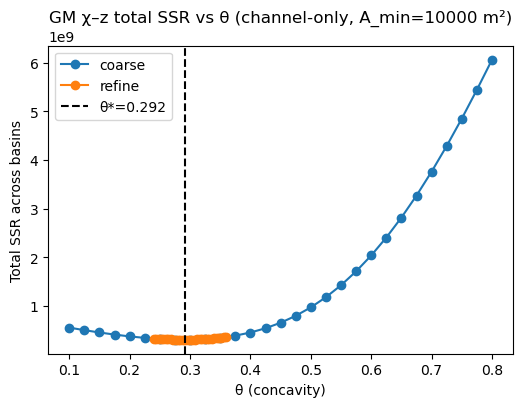


[QUALITY @ θ*=0.292]
  ks median=1.9142
  RMSE (m): median=1.49  IQR=(0.34, 4.02)  min/max=(0.00, 31.89)  n=16010
  R²₀:      median=0.987  IQR=(0.966, 0.995)  min/max=(0.035, 1.000)  n=15998
  nRMSE:    median=0.066  IQR=(0.042, 0.107)
  Global RMS per point ≈ 13.05 m


In [5]:
# ===============================================
# χ-based concavity optimization (final settings)
# Channel-only χ (stream_A_min = A_MIN), no caps
# With option to bypass outlet filtering and use ALL outlets
# ===============================================
import numpy as np, math, time
import matplotlib.pyplot as plt
from TopoAnalysis import dem as d

# -----------------------
# 0) Dataset registry
# -----------------------
DATA = {
    "AP": dict(
        elev="data/taylors_original_dataset/AP_filled",
        area="data/taylors_original_dataset/AP_area",
        flow="data/taylors_original_dataset/AP_fd",
        A_MIN=5.04e4,  # Taylor's AP channel threshold (m^2)
    ),
    "GM": dict(
        elev="data/taylors_original_dataset/GM_10mN_filled",  # or GM_10mN_filled / combined
        area="data/taylors_original_dataset/GM_10mN_area",
        flow="data/taylors_original_dataset/GM_10mN_fd",
        A_MIN=1.0e4,   # Taylor's GM channel threshold (m^2)
    ),
}

# -----------------------
# 1) Choose dataset + knobs
# -----------------------
tag = "GM"  # <-- change to "GM" as needed
USE_ALL_OUTLETS = True   # <-- set True to bypass filtering and use ALL coastline outlets
N_BASINS = None          # optional cap (e.g., 1000); None = use all selected

cfg = DATA[tag]
A_MIN = cfg["A_MIN"]

# -----------------------
# 2) Load grids
# -----------------------
elev = d.Elevation.load(cfg["elev"])
area = d.Area.load(cfg["area"])
fd   = d.FlowDirectionD8.load(cfg["flow"])

Z, A = elev._griddata, area._griddata
ny, nx = Z.shape
dx = elev._georef_info.dx

assert np.isfinite(Z).any(), "Elevation grid has no finite values."
assert np.isfinite(A).any() and (np.nanmax(A) > 0), "Area grid invalid."
print(f"[LOAD] {tag}: grid {ny}×{nx}, dx={dx} m")

# -----------------------
# 3) Coastline outlets → (optionally) filter
# -----------------------
outlets_xy = elev.outlets_at_coastlines()
rc_all = elev._xy_to_rowscols(list(outlets_xy))
print(f"[OUTLETS] coastline outlets: {len(rc_all)}")

def upstream_deg(i, j):
    c = 0
    for (ui, uj) in fd.get_upstream_cell_indexes(i, j):
        if ui is None or uj is None: 
            continue
        if 0 <= ui < ny and 0 <= uj < nx and np.isfinite(Z[ui, uj]):
            c += 1
    return c

if USE_ALL_OUTLETS:
    # Use ALL outlets; attach area if finite (NaN otherwise). No filtering here.
    chosen_all = []
    for (i, j) in rc_all:
        aij = A[i, j] if (0 <= i < ny and 0 <= j < nx) else np.nan
        chosen_all.append((i, j, float(aij) if np.isfinite(aij) else np.nan))
    print(f"[SELECT] Using ALL coastline outlets: {len(chosen_all)} (no filtering)")
    chosen = chosen_all
else:
    # Original “good outlet” filter
    good_rc, nan_elev, small_area, no_up = [], 0, 0, 0
    for (i, j) in rc_all:
        if not (0 <= i < ny and 0 <= j < nx): 
            continue
        if not np.isfinite(Z[i, j]): 
            nan_elev += 1; 
            continue
        if not (np.isfinite(A[i, j]) and A[i, j] >= A_MIN):
            small_area += 1; 
            continue
        if upstream_deg(i, j) <= 0:
            no_up += 1
            continue
        good_rc.append((i, j, float(A[i, j])))
    good_rc.sort(key=lambda t: (np.nan_to_num(t[2], nan=-1.0)), reverse=True)
    print(f"[FILTER] kept={len(good_rc)} | rejected (nan_elev={nan_elev}, small_area={small_area}, no_up={no_up})")
    chosen = good_rc

# Optional cap
if (N_BASINS is not None) and (len(chosen) > N_BASINS):
    idxs = np.linspace(0, len(chosen)-1, N_BASINS).astype(int)
    chosen = [chosen[i] for i in idxs]
print(f"[BASINS] using {len(chosen)} basins for θ optimization")

# -----------------------
# 4) χ traversal (channel-only, no caps)
# -----------------------
def chi_traverse(theta, root_ij, A, Z, fd, dx, stream_A_min):
    """
    Compute (chi, z - z0) for one basin by upstream D8 walk.
    Channel-only: require A >= stream_A_min.
    No visit/time caps.
    """
    (ri, rj) = root_ij
    if not (0 <= ri < ny and 0 <= rj < nx) or not np.isfinite(Z[ri, rj]):
        return np.empty(0), np.empty(0)

    def Apow(i, j):
        a = A[i, j]
        return (a ** (-theta)) if (a > 0 and np.isfinite(a)) else np.nan

    def seg_len(pi, pj, ui, uj):
        return dx * (math.sqrt(2.0) if (abs(ui - pi) == 1 and abs(uj - pj) == 1) else 1.0)

    z0 = Z[ri, rj]
    chi_vals, z_vals = [0.0], [0.0]
    visited = np.zeros_like(Z, dtype=bool)
    visited[ri, rj] = True
    stack = [((ri, rj), 0.0)]

    while stack:
        (pi, pj), parent_chi = stack.pop()
        for (ui, uj) in fd.get_upstream_cell_indexes(pi, pj):
            if ui is None or uj is None: 
                continue
            if ui < 0 or uj < 0 or ui >= ny or uj >= nx:
                continue
            if visited[ui, uj]: 
                continue
            if not np.isfinite(Z[ui, uj]): 
                continue
            if not (np.isfinite(A[ui, uj]) and A[ui, uj] >= stream_A_min):
                continue

            a1, a2 = Apow(pi, pj), Apow(ui, uj)
            next_chi = parent_chi
            if np.isfinite(a1) and np.isfinite(a2):
                next_chi = parent_chi + 0.5 * (a1 + a2) * seg_len(pi, pj, ui, uj)

            chi_vals.append(next_chi)
            z_vals.append(Z[ui, uj] - z0)
            visited[ui, uj] = True
            stack.append(((ui, uj), next_chi))

    x = np.asarray(chi_vals, float); y = np.asarray(z_vals, float)
    m = np.isfinite(x) & np.isfinite(y) & (x > 0.0)
    return x[m], y[m]

def ols_origin(x, y):
    if x.size < 3:
        return np.nan, np.nan
    den = float(np.dot(x, x))
    if den <= 0 or not np.isfinite(den):
        return np.nan, np.nan
    k = float(np.dot(x, y) / den)
    r = y - k * x
    return k, float(np.dot(r, r))

# -----------------------
# 5) θ optimization (coarse→refine) on total SSR across basins
# -----------------------
def total_ssr_for_theta(theta, outlets):
    total = 0.0
    for (i0, j0, _a0) in outlets:
        x, y = chi_traverse(theta, (i0, j0), A, Z, fd, dx, stream_A_min=A_MIN)
        _k, ssr = ols_origin(x, y)
        if np.isfinite(ssr):
            total += ssr
    return total

print("[OPT] coarse sweep …")
coarse_thetas = np.linspace(0.10, 0.80, 29)
coarse = []
t0 = time.time()
for th in coarse_thetas:
    coarse.append((th, total_ssr_for_theta(th, chosen)))
print(f"[OPT] coarse done in {time.time()-t0:.1f}s")

best_th_coarse, best_ssr_coarse = min(coarse, key=lambda kv: kv[1])
lo = max(0.10, best_th_coarse - 0.06)
hi = min(0.80, best_th_coarse + 0.06)

print(f"[OPT] refine around θ={best_th_coarse:.3f} → [{lo:.3f}, {hi:.3f}] …")
refine_thetas = np.linspace(lo, hi, 31)
refine = []
t1 = time.time()
for th in refine_thetas:
    refine.append((th, total_ssr_for_theta(th, chosen)))
print(f"[OPT] refine done in {time.time()-t1:.1f}s")

best_th_refine, best_ssr_refine = min(refine, key=lambda kv: kv[1])
theta_star = best_th_refine
print(f"\n[RESULT] θ*_coarse={best_th_coarse:.3f}  SSR={best_ssr_coarse:.3e}")
print(f"[RESULT] θ*_refine={best_th_refine:.3f}  SSR={best_ssr_refine:.3e}")

plt.figure(figsize=(6,4))
plt.plot([t for t,_ in coarse], [s for _,s in coarse], 'o-', label='coarse')
plt.plot([t for t,_ in refine], [s for _,s in refine], 'o-', label='refine')
plt.axvline(best_th_refine, color='k', ls='--', label=f'θ*={best_th_refine:.3f}')
plt.xlabel("θ (concavity)"); plt.ylabel("Total SSR across basins")
plt.title(f"{tag} χ–z total SSR vs θ (channel-only, A_min={A_MIN:.0f} m²)")
plt.legend(); plt.show()

# -----------------------
# 6) Fit-quality diagnostics at θ*
# -----------------------
def r2_through_origin(y, yhat):
    ssr = float(np.dot((y - yhat), (y - yhat)))
    denom = float(np.dot(y, y))
    if denom <= 0 or not np.isfinite(denom):
        return np.nan, ssr
    return 1.0 - ssr / denom, ssr

rows = []
total_n = 0
total_ssr = 0.0
for bi, (i0, j0, a0) in enumerate(chosen, 1):
    x, y = chi_traverse(theta_star, (i0, j0), A, Z, fd, dx, stream_A_min=A_MIN)
    if x.size < 3:
        rows.append(dict(basin=bi, n=0, ks=np.nan, rmse=np.nan, r2=np.nan,
                         ssr=np.nan, relief=np.nan, nrmse=np.nan))
        continue
    den = float(np.dot(x, x))
    ks = float(np.dot(x, y) / den) if den > 0 else np.nan
    yhat = ks * x if np.isfinite(ks) else np.full_like(y, np.nan)
    R2, ssr = r2_through_origin(y, yhat)
    rmse = math.sqrt(ssr / y.size)
    relief = (np.nanmax(y) - np.nanmin(y)) if y.size > 0 else np.nan
    nrmse = (rmse / relief) if (relief and relief > 0) else np.nan

    total_n += y.size
    if np.isfinite(ssr): total_ssr += ssr
    rows.append(dict(basin=bi, n=int(y.size), ks=ks, rmse=rmse, r2=R2,
                     ssr=ssr, relief=relief, nrmse=nrmse))

def stats(arr):
    arr = np.array([v for v in arr if np.isfinite(v)])
    if arr.size == 0:
        return dict(med=np.nan, p25=np.nan, p75=np.nan, mn=np.nan, mx=np.nan, n=0)
    return dict(med=float(np.median(arr)),
                p25=float(np.percentile(arr, 25)),
                p75=float(np.percentile(arr, 75)),
                mn=float(np.min(arr)), mx=float(np.max(arr)), n=int(arr.size))

rmse_stats = stats([r['rmse'] for r in rows])
r2_stats   = stats([r['r2']   for r in rows])
nrmse_stats= stats([r['nrmse']for r in rows])
rms_total  = math.sqrt(total_ssr / total_n) if (total_n and total_ssr > 0) else np.nan

print(f"\n[QUALITY @ θ*={theta_star:.3f}]")
print(f"  ks median={np.nanmedian([r['ks'] for r in rows]):.4f}")
print(f"  RMSE (m): median={rmse_stats['med']:.2f}  IQR=({rmse_stats['p25']:.2f}, {rmse_stats['p75']:.2f})  "
      f"min/max=({rmse_stats['mn']:.2f}, {rmse_stats['mx']:.2f})  n={rmse_stats['n']}")
print(f"  R²₀:      median={r2_stats['med']:.3f}  IQR=({r2_stats['p25']:.3f}, {r2_stats['p75']:.3f})  "
      f"min/max=({r2_stats['mn']:.3f}, {r2_stats['mx']:.3f})  n={r2_stats['n']}")
print(f"  nRMSE:    median={nrmse_stats['med']:.3f}  IQR=({nrmse_stats['p25']:.3f}, {nrmse_stats['p75']:.3f})")
print(f"  Global RMS per point ≈ {rms_total:.2f} m")


[LOAD] GM: grid 3881×3783, dx=10.0 m
[OUTLETS] coastline outlets: 525422
[SELECT] Using ALL coastline outlets: 525422 (no filtering)
[BASINS] using 525422 basins for θ optimization
[OPT] coarse sweep …
[OPT] coarse done in 23762.0s
[OPT] refine around θ=0.225 → [0.165, 0.285] …
[OPT] refine done in 16073.4s

[RESULT] θ*_coarse=0.225  SSR=1.900e+09
[RESULT] θ*_refine=0.237  SSR=1.895e+09


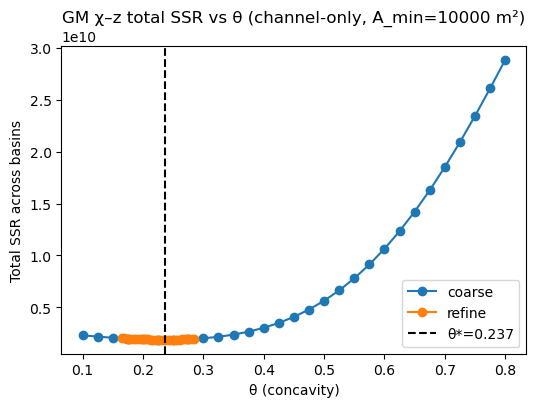


[QUALITY @ θ*=0.237]
  ks median=0.5283
  RMSE (m): median=1.02  IQR=(0.19, 3.59)  min/max=(0.00, 49.71)  n=23617
  R²₀:      median=0.986  IQR=(0.963, 0.996)  min/max=(0.000, 1.000)  n=23617
  nRMSE:    median=0.070  IQR=(0.040, 0.106)
  Global RMS per point ≈ 19.96 m


In [6]:
# ===============================================
# χ-based concavity optimization (final settings)
# Channel-only χ (stream_A_min = A_MIN), no caps
# With option to bypass outlet filtering and use ALL outlets
# ===============================================
import numpy as np, math, time
import matplotlib.pyplot as plt
from TopoAnalysis import dem as d

# -----------------------
# 0) Dataset registry
# -----------------------
DATA = {
    "AP": dict(
        elev="data/taylors_original_dataset/AP_filled",
        area="data/taylors_original_dataset/AP_area",
        flow="data/taylors_original_dataset/AP_fd",
        A_MIN=5.04e4,  # Taylor's AP channel threshold (m^2)
    ),
    "GM": dict(
        elev="data/taylors_original_dataset/GM_10mS_filled",  # or GM_10mN_filled / combined
        area="data/taylors_original_dataset/GM_10mS_area",
        flow="data/taylors_original_dataset/GM_10mS_fd",
        A_MIN=1.0e4,   # Taylor's GM channel threshold (m^2)
    ),
}

# -----------------------
# 1) Choose dataset + knobs
# -----------------------
tag = "GM"  # <-- change to "GM" as needed
USE_ALL_OUTLETS = True   # <-- set True to bypass filtering and use ALL coastline outlets
N_BASINS = None          # optional cap (e.g., 1000); None = use all selected

cfg = DATA[tag]
A_MIN = cfg["A_MIN"]

# -----------------------
# 2) Load grids
# -----------------------
elev = d.Elevation.load(cfg["elev"])
area = d.Area.load(cfg["area"])
fd   = d.FlowDirectionD8.load(cfg["flow"])

Z, A = elev._griddata, area._griddata
ny, nx = Z.shape
dx = elev._georef_info.dx

assert np.isfinite(Z).any(), "Elevation grid has no finite values."
assert np.isfinite(A).any() and (np.nanmax(A) > 0), "Area grid invalid."
print(f"[LOAD] {tag}: grid {ny}×{nx}, dx={dx} m")

# -----------------------
# 3) Coastline outlets → (optionally) filter
# -----------------------
outlets_xy = elev.outlets_at_coastlines()
rc_all = elev._xy_to_rowscols(list(outlets_xy))
print(f"[OUTLETS] coastline outlets: {len(rc_all)}")

def upstream_deg(i, j):
    c = 0
    for (ui, uj) in fd.get_upstream_cell_indexes(i, j):
        if ui is None or uj is None: 
            continue
        if 0 <= ui < ny and 0 <= uj < nx and np.isfinite(Z[ui, uj]):
            c += 1
    return c

if USE_ALL_OUTLETS:
    # Use ALL outlets; attach area if finite (NaN otherwise). No filtering here.
    chosen_all = []
    for (i, j) in rc_all:
        aij = A[i, j] if (0 <= i < ny and 0 <= j < nx) else np.nan
        chosen_all.append((i, j, float(aij) if np.isfinite(aij) else np.nan))
    print(f"[SELECT] Using ALL coastline outlets: {len(chosen_all)} (no filtering)")
    chosen = chosen_all
else:
    # Original “good outlet” filter
    good_rc, nan_elev, small_area, no_up = [], 0, 0, 0
    for (i, j) in rc_all:
        if not (0 <= i < ny and 0 <= j < nx): 
            continue
        if not np.isfinite(Z[i, j]): 
            nan_elev += 1; 
            continue
        if not (np.isfinite(A[i, j]) and A[i, j] >= A_MIN):
            small_area += 1; 
            continue
        if upstream_deg(i, j) <= 0:
            no_up += 1
            continue
        good_rc.append((i, j, float(A[i, j])))
    good_rc.sort(key=lambda t: (np.nan_to_num(t[2], nan=-1.0)), reverse=True)
    print(f"[FILTER] kept={len(good_rc)} | rejected (nan_elev={nan_elev}, small_area={small_area}, no_up={no_up})")
    chosen = good_rc

# Optional cap
if (N_BASINS is not None) and (len(chosen) > N_BASINS):
    idxs = np.linspace(0, len(chosen)-1, N_BASINS).astype(int)
    chosen = [chosen[i] for i in idxs]
print(f"[BASINS] using {len(chosen)} basins for θ optimization")

# -----------------------
# 4) χ traversal (channel-only, no caps)
# -----------------------
def chi_traverse(theta, root_ij, A, Z, fd, dx, stream_A_min):
    """
    Compute (chi, z - z0) for one basin by upstream D8 walk.
    Channel-only: require A >= stream_A_min.
    No visit/time caps.
    """
    (ri, rj) = root_ij
    if not (0 <= ri < ny and 0 <= rj < nx) or not np.isfinite(Z[ri, rj]):
        return np.empty(0), np.empty(0)

    def Apow(i, j):
        a = A[i, j]
        return (a ** (-theta)) if (a > 0 and np.isfinite(a)) else np.nan

    def seg_len(pi, pj, ui, uj):
        return dx * (math.sqrt(2.0) if (abs(ui - pi) == 1 and abs(uj - pj) == 1) else 1.0)

    z0 = Z[ri, rj]
    chi_vals, z_vals = [0.0], [0.0]
    visited = np.zeros_like(Z, dtype=bool)
    visited[ri, rj] = True
    stack = [((ri, rj), 0.0)]

    while stack:
        (pi, pj), parent_chi = stack.pop()
        for (ui, uj) in fd.get_upstream_cell_indexes(pi, pj):
            if ui is None or uj is None: 
                continue
            if ui < 0 or uj < 0 or ui >= ny or uj >= nx:
                continue
            if visited[ui, uj]: 
                continue
            if not np.isfinite(Z[ui, uj]): 
                continue
            if not (np.isfinite(A[ui, uj]) and A[ui, uj] >= stream_A_min):
                continue

            a1, a2 = Apow(pi, pj), Apow(ui, uj)
            next_chi = parent_chi
            if np.isfinite(a1) and np.isfinite(a2):
                next_chi = parent_chi + 0.5 * (a1 + a2) * seg_len(pi, pj, ui, uj)

            chi_vals.append(next_chi)
            z_vals.append(Z[ui, uj] - z0)
            visited[ui, uj] = True
            stack.append(((ui, uj), next_chi))

    x = np.asarray(chi_vals, float); y = np.asarray(z_vals, float)
    m = np.isfinite(x) & np.isfinite(y) & (x > 0.0)
    return x[m], y[m]

def ols_origin(x, y):
    if x.size < 3:
        return np.nan, np.nan
    den = float(np.dot(x, x))
    if den <= 0 or not np.isfinite(den):
        return np.nan, np.nan
    k = float(np.dot(x, y) / den)
    r = y - k * x
    return k, float(np.dot(r, r))

# -----------------------
# 5) θ optimization (coarse→refine) on total SSR across basins
# -----------------------
def total_ssr_for_theta(theta, outlets):
    total = 0.0
    for (i0, j0, _a0) in outlets:
        x, y = chi_traverse(theta, (i0, j0), A, Z, fd, dx, stream_A_min=A_MIN)
        _k, ssr = ols_origin(x, y)
        if np.isfinite(ssr):
            total += ssr
    return total

print("[OPT] coarse sweep …")
coarse_thetas = np.linspace(0.10, 0.80, 29)
coarse = []
t0 = time.time()
for th in coarse_thetas:
    coarse.append((th, total_ssr_for_theta(th, chosen)))
print(f"[OPT] coarse done in {time.time()-t0:.1f}s")

best_th_coarse, best_ssr_coarse = min(coarse, key=lambda kv: kv[1])
lo = max(0.10, best_th_coarse - 0.06)
hi = min(0.80, best_th_coarse + 0.06)

print(f"[OPT] refine around θ={best_th_coarse:.3f} → [{lo:.3f}, {hi:.3f}] …")
refine_thetas = np.linspace(lo, hi, 31)
refine = []
t1 = time.time()
for th in refine_thetas:
    refine.append((th, total_ssr_for_theta(th, chosen)))
print(f"[OPT] refine done in {time.time()-t1:.1f}s")

best_th_refine, best_ssr_refine = min(refine, key=lambda kv: kv[1])
theta_star = best_th_refine
print(f"\n[RESULT] θ*_coarse={best_th_coarse:.3f}  SSR={best_ssr_coarse:.3e}")
print(f"[RESULT] θ*_refine={best_th_refine:.3f}  SSR={best_ssr_refine:.3e}")

plt.figure(figsize=(6,4))
plt.plot([t for t,_ in coarse], [s for _,s in coarse], 'o-', label='coarse')
plt.plot([t for t,_ in refine], [s for _,s in refine], 'o-', label='refine')
plt.axvline(best_th_refine, color='k', ls='--', label=f'θ*={best_th_refine:.3f}')
plt.xlabel("θ (concavity)"); plt.ylabel("Total SSR across basins")
plt.title(f"{tag} χ–z total SSR vs θ (channel-only, A_min={A_MIN:.0f} m²)")
plt.legend(); plt.show()

# -----------------------
# 6) Fit-quality diagnostics at θ*
# -----------------------
def r2_through_origin(y, yhat):
    ssr = float(np.dot((y - yhat), (y - yhat)))
    denom = float(np.dot(y, y))
    if denom <= 0 or not np.isfinite(denom):
        return np.nan, ssr
    return 1.0 - ssr / denom, ssr

rows = []
total_n = 0
total_ssr = 0.0
for bi, (i0, j0, a0) in enumerate(chosen, 1):
    x, y = chi_traverse(theta_star, (i0, j0), A, Z, fd, dx, stream_A_min=A_MIN)
    if x.size < 3:
        rows.append(dict(basin=bi, n=0, ks=np.nan, rmse=np.nan, r2=np.nan,
                         ssr=np.nan, relief=np.nan, nrmse=np.nan))
        continue
    den = float(np.dot(x, x))
    ks = float(np.dot(x, y) / den) if den > 0 else np.nan
    yhat = ks * x if np.isfinite(ks) else np.full_like(y, np.nan)
    R2, ssr = r2_through_origin(y, yhat)
    rmse = math.sqrt(ssr / y.size)
    relief = (np.nanmax(y) - np.nanmin(y)) if y.size > 0 else np.nan
    nrmse = (rmse / relief) if (relief and relief > 0) else np.nan

    total_n += y.size
    if np.isfinite(ssr): total_ssr += ssr
    rows.append(dict(basin=bi, n=int(y.size), ks=ks, rmse=rmse, r2=R2,
                     ssr=ssr, relief=relief, nrmse=nrmse))

def stats(arr):
    arr = np.array([v for v in arr if np.isfinite(v)])
    if arr.size == 0:
        return dict(med=np.nan, p25=np.nan, p75=np.nan, mn=np.nan, mx=np.nan, n=0)
    return dict(med=float(np.median(arr)),
                p25=float(np.percentile(arr, 25)),
                p75=float(np.percentile(arr, 75)),
                mn=float(np.min(arr)), mx=float(np.max(arr)), n=int(arr.size))

rmse_stats = stats([r['rmse'] for r in rows])
r2_stats   = stats([r['r2']   for r in rows])
nrmse_stats= stats([r['nrmse']for r in rows])
rms_total  = math.sqrt(total_ssr / total_n) if (total_n and total_ssr > 0) else np.nan

print(f"\n[QUALITY @ θ*={theta_star:.3f}]")
print(f"  ks median={np.nanmedian([r['ks'] for r in rows]):.4f}")
print(f"  RMSE (m): median={rmse_stats['med']:.2f}  IQR=({rmse_stats['p25']:.2f}, {rmse_stats['p75']:.2f})  "
      f"min/max=({rmse_stats['mn']:.2f}, {rmse_stats['mx']:.2f})  n={rmse_stats['n']}")
print(f"  R²₀:      median={r2_stats['med']:.3f}  IQR=({r2_stats['p25']:.3f}, {r2_stats['p75']:.3f})  "
      f"min/max=({r2_stats['mn']:.3f}, {r2_stats['mx']:.3f})  n={r2_stats['n']}")
print(f"  nRMSE:    median={nrmse_stats['med']:.3f}  IQR=({nrmse_stats['p25']:.3f}, {nrmse_stats['p75']:.3f})")
print(f"  Global RMS per point ≈ {rms_total:.2f} m")


[LOAD] AP: grid 2202×3010, dx=30.0 m
[OUTLETS] coastline outlets: 118379
[SELECT] Using ALL coastline outlets: 118379 (no filtering)
[BASINS] using 118379 basins for θ optimization
[OPT] coarse sweep …
[OPT] coarse TRAP done in 1749.0s
[OPT] coarse LIB  done in 2162.8s
[OPT] refine TRAP around θ=0.525 …
[OPT] refine TRAP done in 934.8s
[OPT] refine LIB  around θ=0.550 …
[OPT] refine LIB  done in 1444.6s

[RESULT] TRAP  θ*_coarse=0.525  SSR=7.918e+07 | θ*_refine=0.537  SSR=7.903e+07
[RESULT] LIB   θ*_coarse=0.550  SSR=6.493e+07 | θ*_refine=0.538  SSR=6.480e+07


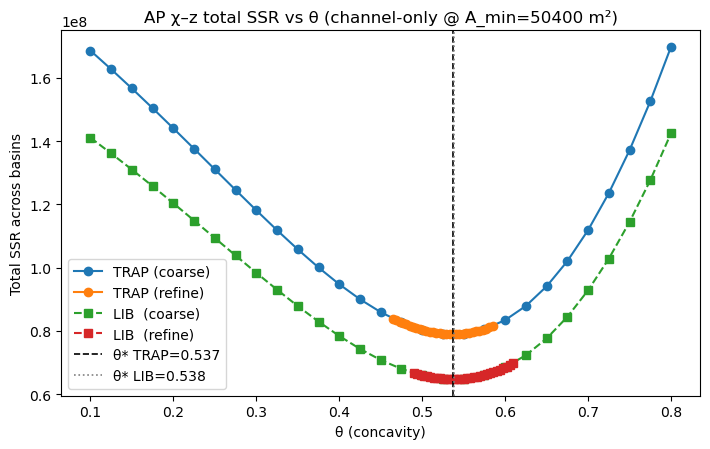


[QUALITY TRAP @ θ*=0.537]
  ks median=47.1781
  RMSE (m):  median=4.32  IQR=(1.68, 8.86)  min/max=(0.00, 32.78)  n=1820
  R²₀:       median=0.974  IQR=(0.954, 0.987)  min/max=(0.000, 1.000)  n=1820
  nRMSE:     median=0.100  IQR=(0.067, 0.143)
  Global RMS per point ≈ 13.19 m

[QUALITY LIB  @ θ*=0.538]
  ks median=49.9844
  RMSE (m):  median=5.01  IQR=(2.08, 9.87)  min/max=(0.00, 71.34)  n=1566
  R²₀:       median=0.968  IQR=(0.936, 0.984)  min/max=(0.001, 1.000)  n=1566
  nRMSE:     median=0.116  IQR=(0.075, 0.181)
  Global RMS per point ≈ 13.07 m

[COMPARE θ*] TRAP vs LIB
  θ* TRAP = 0.5370 | θ* LIB = 0.5380 | Δ = +0.0010

[NOTE]
• LIB χ is read from d.Chi and offset by each basin’s outlet χ so outlet χ=0 (to match TRAP convention).
• Channel-only enforcement is applied when collecting regression pairs (A >= A_MIN) for BOTH methods.
• Using Ao=1.0 makes LIB χ directly comparable; different Ao would only rescale χ and ks but not θ*.


In [7]:
# ===============================================
# χ-based concavity optimization (comparison version)
# Compare: (A) our trapezoid χ traversal vs. (B) TopoAnalysis d.Chi
# Channel-only points are enforced at *regression time* (A >= A_MIN)
# ===============================================
import numpy as np, math, time
import matplotlib.pyplot as plt
from TopoAnalysis import dem as d

# -----------------------
# 0) Dataset registry
# -----------------------
DATA = {
    "AP": dict(
        elev="data/taylors_original_dataset/AP_filled",
        area="data/taylors_original_dataset/AP_area",
        flow="data/taylors_original_dataset/AP_fd",
        A_MIN=5.04e4,  # Taylor's AP channel threshold (m^2)
    ),
    "GM": dict(
        elev="data/taylors_original_dataset/GM_10mS_filled",  # or GM_10mN_filled / combined
        area="data/taylors_original_dataset/GM_10mS_area",
        flow="data/taylors_original_dataset/GM_10mS_fd",
        A_MIN=1.0e4,   # Taylor's GM channel threshold (m^2)
    ),
}

# -----------------------
# 1) Choose dataset + knobs
# -----------------------
tag = "AP"               # <-- "AP" or "GM"
USE_ALL_OUTLETS = True   # True = bypass filtering and use ALL coastline outlets
N_BASINS = None          # optional cap (e.g., 1000)
Ao_LIB = 1.0             # Ao used by library Chi (Ao=1.0 keeps scale consistent)

cfg = DATA[tag]
A_MIN = cfg["A_MIN"]

# -----------------------
# 2) Load grids
# -----------------------
elev = d.Elevation.load(cfg["elev"])
area = d.Area.load(cfg["area"])
fd   = d.FlowDirectionD8.load(cfg["flow"])

Z, A = elev._griddata, area._griddata
ny, nx = Z.shape
dx = elev._georef_info.dx

assert np.isfinite(Z).any(), "Elevation grid has no finite values."
assert np.isfinite(A).any() and (np.nanmax(A) > 0), "Area grid invalid."
print(f"[LOAD] {tag}: grid {ny}×{nx}, dx={dx} m")

# -----------------------
# 3) Coastline outlets → (optionally) filter
# -----------------------
outlets_xy = elev.outlets_at_coastlines()
rc_all = elev._xy_to_rowscols(list(outlets_xy))
print(f"[OUTLETS] coastline outlets: {len(rc_all)}")

def upstream_deg(i, j):
    c = 0
    for (ui, uj) in fd.get_upstream_cell_indexes(i, j):
        if ui is None or uj is None:
            continue
        if 0 <= ui < ny and 0 <= uj < nx and np.isfinite(Z[ui, uj]):
            c += 1
    return c

if USE_ALL_OUTLETS:
    chosen = []
    for (i, j) in rc_all:
        aij = A[i, j] if (0 <= i < ny and 0 <= j < nx) else np.nan
        chosen.append((i, j, float(aij) if np.isfinite(aij) else np.nan))
    print(f"[SELECT] Using ALL coastline outlets: {len(chosen)} (no filtering)")
else:
    good_rc, nan_elev, small_area, no_up = [], 0, 0, 0
    for (i, j) in rc_all:
        if not (0 <= i < ny and 0 <= j < nx): 
            continue
        if not np.isfinite(Z[i, j]):
            nan_elev += 1; continue
        if not (np.isfinite(A[i, j]) and A[i, j] >= A_MIN):
            small_area += 1; continue
        if upstream_deg(i, j) <= 0:
            no_up += 1; continue
        good_rc.append((i, j, float(A[i, j])))
    good_rc.sort(key=lambda t: (np.nan_to_num(t[2], nan=-1.0)), reverse=True)
    print(f"[FILTER] kept={len(good_rc)} | rejected (nan_elev={nan_elev}, small_area={small_area}, no_up={no_up})")
    chosen = good_rc

if (N_BASINS is not None) and (len(chosen) > N_BASINS):
    idxs = np.linspace(0, len(chosen)-1, N_BASINS).astype(int)
    chosen = [chosen[i] for i in idxs]
print(f"[BASINS] using {len(chosen)} basins for θ optimization")

# -----------------------
# 4A) Our χ traversal (trapezoid rule, outlet χ=0)
# -----------------------
def chi_traverse_trap(theta, root_ij, A, Z, fd, dx, stream_A_min):
    (ri, rj) = root_ij
    if not (0 <= ri < ny and 0 <= rj < nx) or not np.isfinite(Z[ri, rj]):
        return np.empty(0), np.empty(0)

    def Apow(i, j):
        a = A[i, j]
        return (a ** (-theta)) if (a > 0 and np.isfinite(a)) else np.nan

    def seg_len(pi, pj, ui, uj):
        return dx * (math.sqrt(2.0) if (abs(ui - pi) == 1 and abs(uj - pj) == 1) else 1.0)

    z0 = Z[ri, rj]
    chi_vals, z_vals = [0.0], [0.0]
    visited = np.zeros_like(Z, dtype=bool)
    visited[ri, rj] = True
    stack = [((ri, rj), 0.0)]

    while stack:
        (pi, pj), parent_chi = stack.pop()
        for (ui, uj) in fd.get_upstream_cell_indexes(pi, pj):
            if ui is None or uj is None: 
                continue
            if ui < 0 or uj < 0 or ui >= ny or uj >= nx:
                continue
            if visited[ui, uj]: 
                continue
            if not np.isfinite(Z[ui, uj]): 
                continue
            if not (np.isfinite(A[ui, uj]) and A[ui, uj] >= stream_A_min):
                continue

            a1, a2 = Apow(pi, pj), Apow(ui, uj)
            next_chi = parent_chi
            if np.isfinite(a1) and np.isfinite(a2):
                next_chi = parent_chi + 0.5 * (a1 + a2) * seg_len(pi, pj, ui, uj)

            chi_vals.append(next_chi)
            z_vals.append(Z[ui, uj] - z0)
            visited[ui, uj] = True
            stack.append(((ui, uj), next_chi))

    x = np.asarray(chi_vals, float); y = np.asarray(z_vals, float)
    m = np.isfinite(x) & np.isfinite(y) & (x > 0.0)
    return x[m], y[m]

# -----------------------
# 4B) Library χ (d.Chi), used to build χ from grid then sample per basin
#      – We offset by the outlet’s χ to compare fairly with (4A).
# -----------------------
def build_lib_chi(theta, Ao=1.0):
    # d.Chi requires outlets as XY; we already have outlets_xy
    chi_obj = d.Chi(area=area, flow_direction=fd, theta=float(theta),
                    Ao=float(Ao), outlets=outlets_xy)
    return chi_obj._griddata.astype(float)

def chi_traverse_lib(theta, root_ij, CHI, Z, A, fd, stream_A_min):
    """
    Read χ from the library grid. To match our regression convention, we:
      • subtract basin-outlet χ so outlet is 0,
      • enforce channel-only points at regression time (A >= A_MIN),
      • traverse the same upstream set via D8 to collect paired (χ, z − z0).
    """
    (ri, rj) = root_ij
    if not (0 <= ri < ny and 0 <= rj < nx) or not np.isfinite(Z[ri, rj]):
        return np.empty(0), np.empty(0)
    if CHI is None or not np.isfinite(CHI[ri, rj]):
        return np.empty(0), np.empty(0)

    z0 = Z[ri, rj]
    chi0 = CHI[ri, rj]  # outlet χ (will be non-zero in the lib implementation)
    visited = np.zeros_like(Z, dtype=bool)
    visited[ri, rj] = True
    stack = [(ri, rj)]
    xs, ys = [], []

    while stack:
        pi, pj = stack.pop()
        for (ui, uj) in fd.get_upstream_cell_indexes(pi, pj):
            if ui is None or uj is None:
                continue
            if ui < 0 or uj < 0 or ui >= ny or uj >= nx:
                continue
            if visited[ui, uj]:
                continue
            if not (np.isfinite(Z[ui, uj]) and np.isfinite(A[ui, uj]) and A[ui, uj] >= stream_A_min):
                continue
            if not np.isfinite(CHI[ui, uj]):
                continue
            # offset χ so outlet is 0, match our convention
            chi_val = CHI[ui, uj] - chi0
            if chi_val <= 0 or not np.isfinite(chi_val):
                continue
            xs.append(chi_val)
            ys.append(Z[ui, uj] - z0)
            visited[ui, uj] = True
            stack.append((ui, uj))

    if len(xs) < 1:
        return np.empty(0), np.empty(0)
    x = np.asarray(xs, float); y = np.asarray(ys, float)
    m = np.isfinite(x) & np.isfinite(y) & (x > 0.0)
    return x[m], y[m]

# -----------------------
# 5) Helpers: OLS through origin & SSR
# -----------------------
def ols_origin(x, y):
    if x.size < 3:
        return np.nan, np.nan
    den = float(np.dot(x, x))
    if den <= 0 or not np.isfinite(den):
        return np.nan, np.nan
    k = float(np.dot(x, y) / den)
    r = y - k * x
    return k, float(np.dot(r, r))

def total_ssr_for_theta(theta, outlets, method, CHI=None):
    total = 0.0
    for (i0, j0, _a0) in outlets:
        if method == "trap":
            x, y = chi_traverse_trap(theta, (i0, j0), A, Z, fd, dx, stream_A_min=A_MIN)
        elif method == "lib":
            x, y = chi_traverse_lib(theta, (i0, j0), CHI, Z, A, fd, stream_A_min=A_MIN)
        else:
            raise ValueError("Unknown method.")
        _k, ssr = ols_origin(x, y)
        if np.isfinite(ssr):
            total += ssr
    return total

# -----------------------
# 6) θ optimization (coarse→refine) for both methods
# -----------------------
print("[OPT] coarse sweep …")
coarse_thetas = np.linspace(0.10, 0.80, 29)

# Build a library χ grid once per θ grid only if needed during sweep;
# for speed, we do two passes: trap (no grid), then lib with per-θ χ grid.
coarse_trap, coarse_lib = [], []

# TRAP coarse
t0 = time.time()
for th in coarse_thetas:
    coarse_trap.append((th, total_ssr_for_theta(th, chosen, method="trap")))
t_trap = time.time()-t0
print(f"[OPT] coarse TRAP done in {t_trap:.1f}s")

# LIB coarse
t0 = time.time()
for th in coarse_thetas:
    CHI = build_lib_chi(th, Ao=Ao_LIB)
    coarse_lib.append((th, total_ssr_for_theta(th, chosen, method="lib", CHI=CHI)))
t_lib = time.time()-t0
print(f"[OPT] coarse LIB  done in {t_lib:.1f}s")

best_th_coarse_trap, best_ssr_coarse_trap = min(coarse_trap, key=lambda kv: kv[1])
best_th_coarse_lib,  best_ssr_coarse_lib  = min(coarse_lib,  key=lambda kv: kv[1])

# Refinement windows centered on each best
def refine_window(th, lo=0.10, hi=0.80, half=0.06):
    lo_ = max(lo, th - half); hi_ = min(hi, th + half)
    return np.linspace(lo_, hi_, 31)

refine_thetas_trap = refine_window(best_th_coarse_trap)
refine_thetas_lib  = refine_window(best_th_coarse_lib)

print(f"[OPT] refine TRAP around θ={best_th_coarse_trap:.3f} …")
refine_trap = []
t1 = time.time()
for th in refine_thetas_trap:
    refine_trap.append((th, total_ssr_for_theta(th, chosen, method="trap")))
print(f"[OPT] refine TRAP done in {time.time()-t1:.1f}s")

print(f"[OPT] refine LIB  around θ={best_th_coarse_lib:.3f} …")
refine_lib = []
t1 = time.time()
for th in refine_thetas_lib:
    CHI = build_lib_chi(th, Ao=Ao_LIB)
    refine_lib.append((th, total_ssr_for_theta(th, chosen, method="lib", CHI=CHI)))
print(f"[OPT] refine LIB  done in {time.time()-t1:.1f}s")

best_th_refine_trap, best_ssr_refine_trap = min(refine_trap, key=lambda kv: kv[1])
best_th_refine_lib,  best_ssr_refine_lib  = min(refine_lib,  key=lambda kv: kv[1])

theta_star_trap = float(best_th_refine_trap)
theta_star_lib  = float(best_th_refine_lib)

print("\n[RESULT] TRAP  θ*_coarse={:.3f}  SSR={:.3e} | θ*_refine={:.3f}  SSR={:.3e}"
      .format(best_th_coarse_trap, best_ssr_coarse_trap, theta_star_trap, best_ssr_refine_trap))
print("[RESULT] LIB   θ*_coarse={:.3f}  SSR={:.3e} | θ*_refine={:.3f}  SSR={:.3e}"
      .format(best_th_coarse_lib,  best_ssr_coarse_lib,  theta_star_lib,  best_ssr_refine_lib))

# -----------------------
# 7) Plot SSR(θ) for both methods
# -----------------------
plt.figure(figsize=(7.2,4.6))
plt.plot([t for t,_ in coarse_trap], [s for _,s in coarse_trap], 'o-', label='TRAP (coarse)')
plt.plot([t for t,_ in refine_trap], [s for _,s in refine_trap], 'o-', label='TRAP (refine)')
plt.plot([t for t,_ in coarse_lib ], [s for _,s in coarse_lib ], 's--', label='LIB  (coarse)')
plt.plot([t for t,_ in refine_lib ], [s for _,s in refine_lib ], 's--', label='LIB  (refine)')
plt.axvline(theta_star_trap, color='k', ls='--', lw=1.2, label=f'θ* TRAP={theta_star_trap:.3f}')
plt.axvline(theta_star_lib,  color='gray', ls=':', lw=1.2, label=f'θ* LIB={theta_star_lib:.3f}')
plt.xlabel("θ (concavity)"); plt.ylabel("Total SSR across basins")
plt.title(f"{tag} χ–z total SSR vs θ (channel-only @ A_min={A_MIN:.0f} m²)")
plt.legend(); plt.tight_layout(); plt.show()

# -----------------------
# 8) Fit-quality diagnostics at each θ*
# -----------------------
def r2_through_origin(y, yhat):
    ssr = float(np.dot((y - yhat), (y - yhat)))
    denom = float(np.dot(y, y))
    if denom <= 0 or not np.isfinite(denom):
        return np.nan, ssr
    return 1.0 - ssr / denom, ssr

def basin_stats(theta, method, CHI=None):
    rows = []
    total_n, total_ssr = 0, 0.0
    for bi, (i0, j0, _a0) in enumerate(chosen, 1):
        if method == "trap":
            x, y = chi_traverse_trap(theta, (i0, j0), A, Z, fd, dx, stream_A_min=A_MIN)
        else:
            x, y = chi_traverse_lib(theta, (i0, j0), CHI, Z, A, fd, stream_A_min=A_MIN)

        if x.size < 3:
            rows.append(dict(basin=bi, n=0, ks=np.nan, rmse=np.nan, r2=np.nan,
                             ssr=np.nan, relief=np.nan, nrmse=np.nan))
            continue

        den = float(np.dot(x, x))
        ks = float(np.dot(x, y) / den) if den > 0 else np.nan
        yhat = ks * x if np.isfinite(ks) else np.full_like(y, np.nan)
        R2, ssr = r2_through_origin(y, yhat)
        rmse = math.sqrt(ssr / y.size)
        relief = (np.nanmax(y) - np.nanmin(y)) if y.size > 0 else np.nan
        nrmse = (rmse / relief) if (relief and relief > 0) else np.nan

        total_n += y.size
        if np.isfinite(ssr): total_ssr += ssr
        rows.append(dict(basin=bi, n=int(y.size), ks=ks, rmse=rmse, r2=R2,
                         ssr=ssr, relief=relief, nrmse=nrmse))

    def stats(arr):
        arr = np.array([v for v in arr if np.isfinite(v)])
        if arr.size == 0:
            return dict(med=np.nan, p25=np.nan, p75=np.nan, mn=np.nan, mx=np.nan, n=0)
        return dict(med=float(np.median(arr)),
                    p25=float(np.percentile(arr, 25)),
                    p75=float(np.percentile(arr, 75)),
                    mn=float(np.min(arr)), mx=float(np.max(arr)), n=int(arr.size))

    rmse_stats = stats([r['rmse'] for r in rows])
    r2_stats   = stats([r['r2']   for r in rows])
    nrmse_stats= stats([r['nrmse']for r in rows])
    rms_total  = math.sqrt(total_ssr / total_n) if (total_n and total_ssr > 0) else np.nan
    ks_med     = np.nanmedian([r['ks'] for r in rows]) if rows else np.nan

    return dict(rows=rows, rmse=rmse_stats, r2=r2_stats, nrmse=nrmse_stats,
                rms_total=rms_total, ks_median=ks_med, total_n=total_n)

# TRAP diagnostics
diag_trap = basin_stats(theta_star_trap, method="trap")
print(f"\n[QUALITY TRAP @ θ*={theta_star_trap:.3f}]")
print(f"  ks median={diag_trap['ks_median']:.4f}")
print(f"  RMSE (m):  median={diag_trap['rmse']['med']:.2f}  IQR=({diag_trap['rmse']['p25']:.2f}, {diag_trap['rmse']['p75']:.2f})"
      f"  min/max=({diag_trap['rmse']['mn']:.2f}, {diag_trap['rmse']['mx']:.2f})  n={diag_trap['rmse']['n']}")
print(f"  R²₀:       median={diag_trap['r2']['med']:.3f}  IQR=({diag_trap['r2']['p25']:.3f}, {diag_trap['r2']['p75']:.3f})"
      f"  min/max=({diag_trap['r2']['mn']:.3f}, {diag_trap['r2']['mx']:.3f})  n={diag_trap['r2']['n']}")
print(f"  nRMSE:     median={diag_trap['nrmse']['med']:.3f}  IQR=({diag_trap['nrmse']['p25']:.3f}, {diag_trap['nrmse']['p75']:.3f})")
print(f"  Global RMS per point ≈ {diag_trap['rms_total']:.2f} m")

# LIB diagnostics (build CHI at θ*=theta_star_lib once)
CHI_star = build_lib_chi(theta_star_lib, Ao=Ao_LIB)
diag_lib = basin_stats(theta_star_lib, method="lib", CHI=CHI_star)
print(f"\n[QUALITY LIB  @ θ*={theta_star_lib:.3f}]")
print(f"  ks median={diag_lib['ks_median']:.4f}")
print(f"  RMSE (m):  median={diag_lib['rmse']['med']:.2f}  IQR=({diag_lib['rmse']['p25']:.2f}, {diag_lib['rmse']['p75']:.2f})"
      f"  min/max=({diag_lib['rmse']['mn']:.2f}, {diag_lib['rmse']['mx']:.2f})  n={diag_lib['rmse']['n']}")
print(f"  R²₀:       median={diag_lib['r2']['med']:.3f}  IQR=({diag_lib['r2']['p25']:.3f}, {diag_lib['r2']['p75']:.3f})"
      f"  min/max=({diag_lib['r2']['mn']:.3f}, {diag_lib['r2']['mx']:.3f})  n={diag_lib['r2']['n']}")
print(f"  nRMSE:     median={diag_lib['nrmse']['med']:.3f}  IQR=({diag_lib['nrmse']['p25']:.3f}, {diag_lib['nrmse']['p75']:.3f})")
print(f"  Global RMS per point ≈ {diag_lib['rms_total']:.2f} m")

# -----------------------
# 9) Quick headline comparison
# -----------------------
print("\n[COMPARE θ*] TRAP vs LIB")
print(f"  θ* TRAP = {theta_star_trap:.4f} | θ* LIB = {theta_star_lib:.4f} | Δ = {theta_star_lib - theta_star_trap:+.4f}")

print("\n[NOTE]")
print("• LIB χ is read from d.Chi and offset by each basin’s outlet χ so outlet χ=0 (to match TRAP convention).")
print("• Channel-only enforcement is applied when collecting regression pairs (A >= A_MIN) for BOTH methods.")
print("• Using Ao=1.0 makes LIB χ directly comparable; different Ao would only rescale χ and ks but not θ*.")


[LOAD] GM: grid 3881×3783, dx=10.0 m
[OUTLETS] coastline outlets: 525422
[SELECT] Using ALL coastline outlets: 525422 (no filtering)
[BASINS] using 525422 basins for θ optimization
[OPT] coarse sweep …
[OPT] coarse TRAP done in 9629.0s
[OPT] coarse LIB  done in 20046.5s
[OPT] refine TRAP around θ=0.225 …
[OPT] refine TRAP done in 16519.4s
[OPT] refine LIB  around θ=0.225 …
[OPT] refine LIB  done in 13187.6s

[RESULT] TRAP  θ*_coarse=0.225  SSR=1.900e+09 | θ*_refine=0.237  SSR=1.895e+09
[RESULT] LIB   θ*_coarse=0.225  SSR=1.539e+09 | θ*_refine=0.233  SSR=1.537e+09


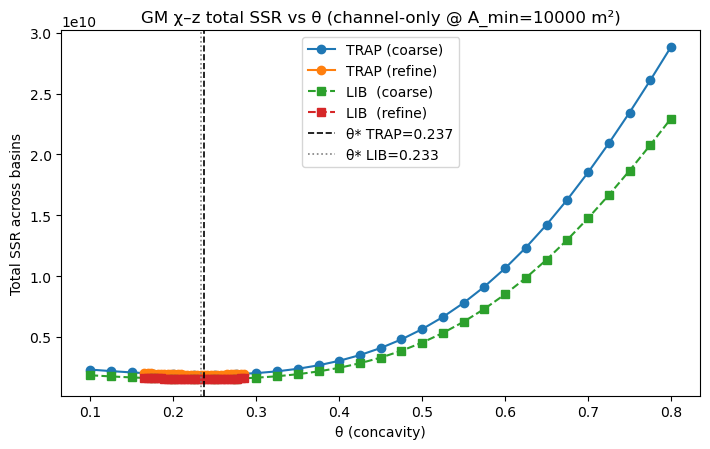


[QUALITY TRAP @ θ*=0.237]
  ks median=0.5283
  RMSE (m):  median=1.02  IQR=(0.19, 3.59)  min/max=(0.00, 49.71)  n=23617
  R²₀:       median=0.986  IQR=(0.963, 0.996)  min/max=(0.000, 1.000)  n=23617
  nRMSE:     median=0.070  IQR=(0.040, 0.106)
  Global RMS per point ≈ 19.96 m

[QUALITY LIB  @ θ*=0.233]
  ks median=0.8906
  RMSE (m):  median=1.52  IQR=(0.31, 4.58)  min/max=(0.00, 49.27)  n=21886
  R²₀:       median=0.973  IQR=(0.901, 0.992)  min/max=(0.000, 1.000)  n=21886
  nRMSE:     median=0.091  IQR=(0.053, 0.178)
  Global RMS per point ≈ 19.38 m

[COMPARE θ*] TRAP vs LIB
  θ* TRAP = 0.2370 | θ* LIB = 0.2330 | Δ = -0.0040

[NOTE]
• LIB χ is read from d.Chi and offset by each basin’s outlet χ so outlet χ=0 (to match TRAP convention).
• Channel-only enforcement is applied when collecting regression pairs (A >= A_MIN) for BOTH methods.
• Using Ao=1.0 makes LIB χ directly comparable; different Ao would only rescale χ and ks but not θ*.


In [8]:
# ===============================================
# χ-based concavity optimization (comparison version)
# Compare: (A) our trapezoid χ traversal vs. (B) TopoAnalysis d.Chi
# Channel-only points are enforced at *regression time* (A >= A_MIN)
# ===============================================
import numpy as np, math, time
import matplotlib.pyplot as plt
from TopoAnalysis import dem as d

# -----------------------
# 0) Dataset registry
# -----------------------
DATA = {
    "AP": dict(
        elev="data/taylors_original_dataset/AP_filled",
        area="data/taylors_original_dataset/AP_area",
        flow="data/taylors_original_dataset/AP_fd",
        A_MIN=5.04e4,  # Taylor's AP channel threshold (m^2)
    ),
    "GM": dict(
        elev="data/taylors_original_dataset/GM_10mS_filled",  # or GM_10mN_filled / combined
        area="data/taylors_original_dataset/GM_10mS_area",
        flow="data/taylors_original_dataset/GM_10mS_fd",
        A_MIN=1.0e4,   # Taylor's GM channel threshold (m^2)
    ),
}

# -----------------------
# 1) Choose dataset + knobs
# -----------------------
tag = "GM"               # <-- "AP" or "GM"
USE_ALL_OUTLETS = True   # True = bypass filtering and use ALL coastline outlets
N_BASINS = None          # optional cap (e.g., 1000)
Ao_LIB = 1.0             # Ao used by library Chi (Ao=1.0 keeps scale consistent)

cfg = DATA[tag]
A_MIN = cfg["A_MIN"]

# -----------------------
# 2) Load grids
# -----------------------
elev = d.Elevation.load(cfg["elev"])
area = d.Area.load(cfg["area"])
fd   = d.FlowDirectionD8.load(cfg["flow"])

Z, A = elev._griddata, area._griddata
ny, nx = Z.shape
dx = elev._georef_info.dx

assert np.isfinite(Z).any(), "Elevation grid has no finite values."
assert np.isfinite(A).any() and (np.nanmax(A) > 0), "Area grid invalid."
print(f"[LOAD] {tag}: grid {ny}×{nx}, dx={dx} m")

# -----------------------
# 3) Coastline outlets → (optionally) filter
# -----------------------
outlets_xy = elev.outlets_at_coastlines()
rc_all = elev._xy_to_rowscols(list(outlets_xy))
print(f"[OUTLETS] coastline outlets: {len(rc_all)}")

def upstream_deg(i, j):
    c = 0
    for (ui, uj) in fd.get_upstream_cell_indexes(i, j):
        if ui is None or uj is None:
            continue
        if 0 <= ui < ny and 0 <= uj < nx and np.isfinite(Z[ui, uj]):
            c += 1
    return c

if USE_ALL_OUTLETS:
    chosen = []
    for (i, j) in rc_all:
        aij = A[i, j] if (0 <= i < ny and 0 <= j < nx) else np.nan
        chosen.append((i, j, float(aij) if np.isfinite(aij) else np.nan))
    print(f"[SELECT] Using ALL coastline outlets: {len(chosen)} (no filtering)")
else:
    good_rc, nan_elev, small_area, no_up = [], 0, 0, 0
    for (i, j) in rc_all:
        if not (0 <= i < ny and 0 <= j < nx): 
            continue
        if not np.isfinite(Z[i, j]):
            nan_elev += 1; continue
        if not (np.isfinite(A[i, j]) and A[i, j] >= A_MIN):
            small_area += 1; continue
        if upstream_deg(i, j) <= 0:
            no_up += 1; continue
        good_rc.append((i, j, float(A[i, j])))
    good_rc.sort(key=lambda t: (np.nan_to_num(t[2], nan=-1.0)), reverse=True)
    print(f"[FILTER] kept={len(good_rc)} | rejected (nan_elev={nan_elev}, small_area={small_area}, no_up={no_up})")
    chosen = good_rc

if (N_BASINS is not None) and (len(chosen) > N_BASINS):
    idxs = np.linspace(0, len(chosen)-1, N_BASINS).astype(int)
    chosen = [chosen[i] for i in idxs]
print(f"[BASINS] using {len(chosen)} basins for θ optimization")

# -----------------------
# 4A) Our χ traversal (trapezoid rule, outlet χ=0)
# -----------------------
def chi_traverse_trap(theta, root_ij, A, Z, fd, dx, stream_A_min):
    (ri, rj) = root_ij
    if not (0 <= ri < ny and 0 <= rj < nx) or not np.isfinite(Z[ri, rj]):
        return np.empty(0), np.empty(0)

    def Apow(i, j):
        a = A[i, j]
        return (a ** (-theta)) if (a > 0 and np.isfinite(a)) else np.nan

    def seg_len(pi, pj, ui, uj):
        return dx * (math.sqrt(2.0) if (abs(ui - pi) == 1 and abs(uj - pj) == 1) else 1.0)

    z0 = Z[ri, rj]
    chi_vals, z_vals = [0.0], [0.0]
    visited = np.zeros_like(Z, dtype=bool)
    visited[ri, rj] = True
    stack = [((ri, rj), 0.0)]

    while stack:
        (pi, pj), parent_chi = stack.pop()
        for (ui, uj) in fd.get_upstream_cell_indexes(pi, pj):
            if ui is None or uj is None: 
                continue
            if ui < 0 or uj < 0 or ui >= ny or uj >= nx:
                continue
            if visited[ui, uj]: 
                continue
            if not np.isfinite(Z[ui, uj]): 
                continue
            if not (np.isfinite(A[ui, uj]) and A[ui, uj] >= stream_A_min):
                continue

            a1, a2 = Apow(pi, pj), Apow(ui, uj)
            next_chi = parent_chi
            if np.isfinite(a1) and np.isfinite(a2):
                next_chi = parent_chi + 0.5 * (a1 + a2) * seg_len(pi, pj, ui, uj)

            chi_vals.append(next_chi)
            z_vals.append(Z[ui, uj] - z0)
            visited[ui, uj] = True
            stack.append(((ui, uj), next_chi))

    x = np.asarray(chi_vals, float); y = np.asarray(z_vals, float)
    m = np.isfinite(x) & np.isfinite(y) & (x > 0.0)
    return x[m], y[m]

# -----------------------
# 4B) Library χ (d.Chi), used to build χ from grid then sample per basin
#      – We offset by the outlet’s χ to compare fairly with (4A).
# -----------------------
def build_lib_chi(theta, Ao=1.0):
    # d.Chi requires outlets as XY; we already have outlets_xy
    chi_obj = d.Chi(area=area, flow_direction=fd, theta=float(theta),
                    Ao=float(Ao), outlets=outlets_xy)
    return chi_obj._griddata.astype(float)

def chi_traverse_lib(theta, root_ij, CHI, Z, A, fd, stream_A_min):
    """
    Read χ from the library grid. To match our regression convention, we:
      • subtract basin-outlet χ so outlet is 0,
      • enforce channel-only points at regression time (A >= A_MIN),
      • traverse the same upstream set via D8 to collect paired (χ, z − z0).
    """
    (ri, rj) = root_ij
    if not (0 <= ri < ny and 0 <= rj < nx) or not np.isfinite(Z[ri, rj]):
        return np.empty(0), np.empty(0)
    if CHI is None or not np.isfinite(CHI[ri, rj]):
        return np.empty(0), np.empty(0)

    z0 = Z[ri, rj]
    chi0 = CHI[ri, rj]  # outlet χ (will be non-zero in the lib implementation)
    visited = np.zeros_like(Z, dtype=bool)
    visited[ri, rj] = True
    stack = [(ri, rj)]
    xs, ys = [], []

    while stack:
        pi, pj = stack.pop()
        for (ui, uj) in fd.get_upstream_cell_indexes(pi, pj):
            if ui is None or uj is None:
                continue
            if ui < 0 or uj < 0 or ui >= ny or uj >= nx:
                continue
            if visited[ui, uj]:
                continue
            if not (np.isfinite(Z[ui, uj]) and np.isfinite(A[ui, uj]) and A[ui, uj] >= stream_A_min):
                continue
            if not np.isfinite(CHI[ui, uj]):
                continue
            # offset χ so outlet is 0, match our convention
            chi_val = CHI[ui, uj] - chi0
            if chi_val <= 0 or not np.isfinite(chi_val):
                continue
            xs.append(chi_val)
            ys.append(Z[ui, uj] - z0)
            visited[ui, uj] = True
            stack.append((ui, uj))

    if len(xs) < 1:
        return np.empty(0), np.empty(0)
    x = np.asarray(xs, float); y = np.asarray(ys, float)
    m = np.isfinite(x) & np.isfinite(y) & (x > 0.0)
    return x[m], y[m]

# -----------------------
# 5) Helpers: OLS through origin & SSR
# -----------------------
def ols_origin(x, y):
    if x.size < 3:
        return np.nan, np.nan
    den = float(np.dot(x, x))
    if den <= 0 or not np.isfinite(den):
        return np.nan, np.nan
    k = float(np.dot(x, y) / den)
    r = y - k * x
    return k, float(np.dot(r, r))

def total_ssr_for_theta(theta, outlets, method, CHI=None):
    total = 0.0
    for (i0, j0, _a0) in outlets:
        if method == "trap":
            x, y = chi_traverse_trap(theta, (i0, j0), A, Z, fd, dx, stream_A_min=A_MIN)
        elif method == "lib":
            x, y = chi_traverse_lib(theta, (i0, j0), CHI, Z, A, fd, stream_A_min=A_MIN)
        else:
            raise ValueError("Unknown method.")
        _k, ssr = ols_origin(x, y)
        if np.isfinite(ssr):
            total += ssr
    return total

# -----------------------
# 6) θ optimization (coarse→refine) for both methods
# -----------------------
print("[OPT] coarse sweep …")
coarse_thetas = np.linspace(0.10, 0.80, 29)

# Build a library χ grid once per θ grid only if needed during sweep;
# for speed, we do two passes: trap (no grid), then lib with per-θ χ grid.
coarse_trap, coarse_lib = [], []

# TRAP coarse
t0 = time.time()
for th in coarse_thetas:
    coarse_trap.append((th, total_ssr_for_theta(th, chosen, method="trap")))
t_trap = time.time()-t0
print(f"[OPT] coarse TRAP done in {t_trap:.1f}s")

# LIB coarse
t0 = time.time()
for th in coarse_thetas:
    CHI = build_lib_chi(th, Ao=Ao_LIB)
    coarse_lib.append((th, total_ssr_for_theta(th, chosen, method="lib", CHI=CHI)))
t_lib = time.time()-t0
print(f"[OPT] coarse LIB  done in {t_lib:.1f}s")

best_th_coarse_trap, best_ssr_coarse_trap = min(coarse_trap, key=lambda kv: kv[1])
best_th_coarse_lib,  best_ssr_coarse_lib  = min(coarse_lib,  key=lambda kv: kv[1])

# Refinement windows centered on each best
def refine_window(th, lo=0.10, hi=0.80, half=0.06):
    lo_ = max(lo, th - half); hi_ = min(hi, th + half)
    return np.linspace(lo_, hi_, 31)

refine_thetas_trap = refine_window(best_th_coarse_trap)
refine_thetas_lib  = refine_window(best_th_coarse_lib)

print(f"[OPT] refine TRAP around θ={best_th_coarse_trap:.3f} …")
refine_trap = []
t1 = time.time()
for th in refine_thetas_trap:
    refine_trap.append((th, total_ssr_for_theta(th, chosen, method="trap")))
print(f"[OPT] refine TRAP done in {time.time()-t1:.1f}s")

print(f"[OPT] refine LIB  around θ={best_th_coarse_lib:.3f} …")
refine_lib = []
t1 = time.time()
for th in refine_thetas_lib:
    CHI = build_lib_chi(th, Ao=Ao_LIB)
    refine_lib.append((th, total_ssr_for_theta(th, chosen, method="lib", CHI=CHI)))
print(f"[OPT] refine LIB  done in {time.time()-t1:.1f}s")

best_th_refine_trap, best_ssr_refine_trap = min(refine_trap, key=lambda kv: kv[1])
best_th_refine_lib,  best_ssr_refine_lib  = min(refine_lib,  key=lambda kv: kv[1])

theta_star_trap = float(best_th_refine_trap)
theta_star_lib  = float(best_th_refine_lib)

print("\n[RESULT] TRAP  θ*_coarse={:.3f}  SSR={:.3e} | θ*_refine={:.3f}  SSR={:.3e}"
      .format(best_th_coarse_trap, best_ssr_coarse_trap, theta_star_trap, best_ssr_refine_trap))
print("[RESULT] LIB   θ*_coarse={:.3f}  SSR={:.3e} | θ*_refine={:.3f}  SSR={:.3e}"
      .format(best_th_coarse_lib,  best_ssr_coarse_lib,  theta_star_lib,  best_ssr_refine_lib))

# -----------------------
# 7) Plot SSR(θ) for both methods
# -----------------------
plt.figure(figsize=(7.2,4.6))
plt.plot([t for t,_ in coarse_trap], [s for _,s in coarse_trap], 'o-', label='TRAP (coarse)')
plt.plot([t for t,_ in refine_trap], [s for _,s in refine_trap], 'o-', label='TRAP (refine)')
plt.plot([t for t,_ in coarse_lib ], [s for _,s in coarse_lib ], 's--', label='LIB  (coarse)')
plt.plot([t for t,_ in refine_lib ], [s for _,s in refine_lib ], 's--', label='LIB  (refine)')
plt.axvline(theta_star_trap, color='k', ls='--', lw=1.2, label=f'θ* TRAP={theta_star_trap:.3f}')
plt.axvline(theta_star_lib,  color='gray', ls=':', lw=1.2, label=f'θ* LIB={theta_star_lib:.3f}')
plt.xlabel("θ (concavity)"); plt.ylabel("Total SSR across basins")
plt.title(f"{tag} χ–z total SSR vs θ (channel-only @ A_min={A_MIN:.0f} m²)")
plt.legend(); plt.tight_layout(); plt.show()

# -----------------------
# 8) Fit-quality diagnostics at each θ*
# -----------------------
def r2_through_origin(y, yhat):
    ssr = float(np.dot((y - yhat), (y - yhat)))
    denom = float(np.dot(y, y))
    if denom <= 0 or not np.isfinite(denom):
        return np.nan, ssr
    return 1.0 - ssr / denom, ssr

def basin_stats(theta, method, CHI=None):
    rows = []
    total_n, total_ssr = 0, 0.0
    for bi, (i0, j0, _a0) in enumerate(chosen, 1):
        if method == "trap":
            x, y = chi_traverse_trap(theta, (i0, j0), A, Z, fd, dx, stream_A_min=A_MIN)
        else:
            x, y = chi_traverse_lib(theta, (i0, j0), CHI, Z, A, fd, stream_A_min=A_MIN)

        if x.size < 3:
            rows.append(dict(basin=bi, n=0, ks=np.nan, rmse=np.nan, r2=np.nan,
                             ssr=np.nan, relief=np.nan, nrmse=np.nan))
            continue

        den = float(np.dot(x, x))
        ks = float(np.dot(x, y) / den) if den > 0 else np.nan
        yhat = ks * x if np.isfinite(ks) else np.full_like(y, np.nan)
        R2, ssr = r2_through_origin(y, yhat)
        rmse = math.sqrt(ssr / y.size)
        relief = (np.nanmax(y) - np.nanmin(y)) if y.size > 0 else np.nan
        nrmse = (rmse / relief) if (relief and relief > 0) else np.nan

        total_n += y.size
        if np.isfinite(ssr): total_ssr += ssr
        rows.append(dict(basin=bi, n=int(y.size), ks=ks, rmse=rmse, r2=R2,
                         ssr=ssr, relief=relief, nrmse=nrmse))

    def stats(arr):
        arr = np.array([v for v in arr if np.isfinite(v)])
        if arr.size == 0:
            return dict(med=np.nan, p25=np.nan, p75=np.nan, mn=np.nan, mx=np.nan, n=0)
        return dict(med=float(np.median(arr)),
                    p25=float(np.percentile(arr, 25)),
                    p75=float(np.percentile(arr, 75)),
                    mn=float(np.min(arr)), mx=float(np.max(arr)), n=int(arr.size))

    rmse_stats = stats([r['rmse'] for r in rows])
    r2_stats   = stats([r['r2']   for r in rows])
    nrmse_stats= stats([r['nrmse']for r in rows])
    rms_total  = math.sqrt(total_ssr / total_n) if (total_n and total_ssr > 0) else np.nan
    ks_med     = np.nanmedian([r['ks'] for r in rows]) if rows else np.nan

    return dict(rows=rows, rmse=rmse_stats, r2=r2_stats, nrmse=nrmse_stats,
                rms_total=rms_total, ks_median=ks_med, total_n=total_n)

# TRAP diagnostics
diag_trap = basin_stats(theta_star_trap, method="trap")
print(f"\n[QUALITY TRAP @ θ*={theta_star_trap:.3f}]")
print(f"  ks median={diag_trap['ks_median']:.4f}")
print(f"  RMSE (m):  median={diag_trap['rmse']['med']:.2f}  IQR=({diag_trap['rmse']['p25']:.2f}, {diag_trap['rmse']['p75']:.2f})"
      f"  min/max=({diag_trap['rmse']['mn']:.2f}, {diag_trap['rmse']['mx']:.2f})  n={diag_trap['rmse']['n']}")
print(f"  R²₀:       median={diag_trap['r2']['med']:.3f}  IQR=({diag_trap['r2']['p25']:.3f}, {diag_trap['r2']['p75']:.3f})"
      f"  min/max=({diag_trap['r2']['mn']:.3f}, {diag_trap['r2']['mx']:.3f})  n={diag_trap['r2']['n']}")
print(f"  nRMSE:     median={diag_trap['nrmse']['med']:.3f}  IQR=({diag_trap['nrmse']['p25']:.3f}, {diag_trap['nrmse']['p75']:.3f})")
print(f"  Global RMS per point ≈ {diag_trap['rms_total']:.2f} m")

# LIB diagnostics (build CHI at θ*=theta_star_lib once)
CHI_star = build_lib_chi(theta_star_lib, Ao=Ao_LIB)
diag_lib = basin_stats(theta_star_lib, method="lib", CHI=CHI_star)
print(f"\n[QUALITY LIB  @ θ*={theta_star_lib:.3f}]")
print(f"  ks median={diag_lib['ks_median']:.4f}")
print(f"  RMSE (m):  median={diag_lib['rmse']['med']:.2f}  IQR=({diag_lib['rmse']['p25']:.2f}, {diag_lib['rmse']['p75']:.2f})"
      f"  min/max=({diag_lib['rmse']['mn']:.2f}, {diag_lib['rmse']['mx']:.2f})  n={diag_lib['rmse']['n']}")
print(f"  R²₀:       median={diag_lib['r2']['med']:.3f}  IQR=({diag_lib['r2']['p25']:.3f}, {diag_lib['r2']['p75']:.3f})"
      f"  min/max=({diag_lib['r2']['mn']:.3f}, {diag_lib['r2']['mx']:.3f})  n={diag_lib['r2']['n']}")
print(f"  nRMSE:     median={diag_lib['nrmse']['med']:.3f}  IQR=({diag_lib['nrmse']['p25']:.3f}, {diag_lib['nrmse']['p75']:.3f})")
print(f"  Global RMS per point ≈ {diag_lib['rms_total']:.2f} m")

# -----------------------
# 9) Quick headline comparison
# -----------------------
print("\n[COMPARE θ*] TRAP vs LIB")
print(f"  θ* TRAP = {theta_star_trap:.4f} | θ* LIB = {theta_star_lib:.4f} | Δ = {theta_star_lib - theta_star_trap:+.4f}")

print("\n[NOTE]")
print("• LIB χ is read from d.Chi and offset by each basin’s outlet χ so outlet χ=0 (to match TRAP convention).")
print("• Channel-only enforcement is applied when collecting regression pairs (A >= A_MIN) for BOTH methods.")
print("• Using Ao=1.0 makes LIB χ directly comparable; different Ao would only rescale χ and ks but not θ*.")


[LOAD] GM: grid 2997×2297, dx=10.0 m
[OUTLETS] coastline outlets: 441765
[SELECT] Using ALL coastline outlets: 441765 (no filtering)
[BASINS] using 441765 basins for θ optimization
[OPT] coarse sweep …
[OPT] coarse TRAP done in 1962.6s
[OPT] coarse LIB  done in 5452.3s
[OPT] refine TRAP around θ=0.300 …
[OPT] refine TRAP done in 2761.6s
[OPT] refine LIB  around θ=0.275 …
[OPT] refine LIB  done in 5641.4s

[RESULT] TRAP  θ*_coarse=0.300  SSR=3.092e+08 | θ*_refine=0.292  SSR=3.084e+08
[RESULT] LIB   θ*_coarse=0.275  SSR=2.696e+08 | θ*_refine=0.287  SSR=2.687e+08


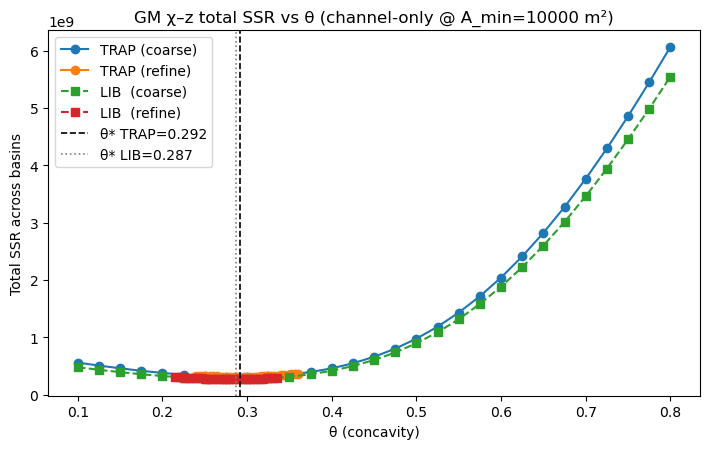


[QUALITY TRAP @ θ*=0.292]
  ks median=1.9142
  RMSE (m):  median=1.49  IQR=(0.34, 4.02)  min/max=(0.00, 31.89)  n=16010
  R²₀:       median=0.987  IQR=(0.966, 0.995)  min/max=(0.035, 1.000)  n=15998
  nRMSE:     median=0.066  IQR=(0.042, 0.107)
  Global RMS per point ≈ 13.05 m

[QUALITY LIB  @ θ*=0.287]
  ks median=2.3252
  RMSE (m):  median=1.95  IQR=(0.50, 5.19)  min/max=(0.00, 46.67)  n=14467
  R²₀:       median=0.979  IQR=(0.927, 0.993)  min/max=(0.000, 1.000)  n=14454
  nRMSE:     median=0.084  IQR=(0.049, 0.152)
  Global RMS per point ≈ 13.36 m

[COMPARE θ*] TRAP vs LIB
  θ* TRAP = 0.2920 | θ* LIB = 0.2870 | Δ = -0.0050

[NOTE]
• LIB χ is read from d.Chi and offset by each basin’s outlet χ so outlet χ=0 (to match TRAP convention).
• Channel-only enforcement is applied when collecting regression pairs (A >= A_MIN) for BOTH methods.
• Using Ao=1.0 makes LIB χ directly comparable; different Ao would only rescale χ and ks but not θ*.


In [9]:
# ===============================================
# χ-based concavity optimization (comparison version)
# Compare: (A) our trapezoid χ traversal vs. (B) TopoAnalysis d.Chi
# Channel-only points are enforced at *regression time* (A >= A_MIN)
# ===============================================
import numpy as np, math, time
import matplotlib.pyplot as plt
from TopoAnalysis import dem as d

# -----------------------
# 0) Dataset registry
# -----------------------
DATA = {
    "AP": dict(
        elev="data/taylors_original_dataset/AP_filled",
        area="data/taylors_original_dataset/AP_area",
        flow="data/taylors_original_dataset/AP_fd",
        A_MIN=5.04e4,  # Taylor's AP channel threshold (m^2)
    ),
    "GM": dict(
        elev="data/taylors_original_dataset/GM_10mN_filled",  # or GM_10mN_filled / combined
        area="data/taylors_original_dataset/GM_10mN_area",
        flow="data/taylors_original_dataset/GM_10mN_fd",
        A_MIN=1.0e4,   # Taylor's GM channel threshold (m^2)
    ),
}

# -----------------------
# 1) Choose dataset + knobs
# -----------------------
tag = "GM"               # <-- "AP" or "GM"
USE_ALL_OUTLETS = True   # True = bypass filtering and use ALL coastline outlets
N_BASINS = None          # optional cap (e.g., 1000)
Ao_LIB = 1.0             # Ao used by library Chi (Ao=1.0 keeps scale consistent)

cfg = DATA[tag]
A_MIN = cfg["A_MIN"]

# -----------------------
# 2) Load grids
# -----------------------
elev = d.Elevation.load(cfg["elev"])
area = d.Area.load(cfg["area"])
fd   = d.FlowDirectionD8.load(cfg["flow"])

Z, A = elev._griddata, area._griddata
ny, nx = Z.shape
dx = elev._georef_info.dx

assert np.isfinite(Z).any(), "Elevation grid has no finite values."
assert np.isfinite(A).any() and (np.nanmax(A) > 0), "Area grid invalid."
print(f"[LOAD] {tag}: grid {ny}×{nx}, dx={dx} m")

# -----------------------
# 3) Coastline outlets → (optionally) filter
# -----------------------
outlets_xy = elev.outlets_at_coastlines()
rc_all = elev._xy_to_rowscols(list(outlets_xy))
print(f"[OUTLETS] coastline outlets: {len(rc_all)}")

def upstream_deg(i, j):
    c = 0
    for (ui, uj) in fd.get_upstream_cell_indexes(i, j):
        if ui is None or uj is None:
            continue
        if 0 <= ui < ny and 0 <= uj < nx and np.isfinite(Z[ui, uj]):
            c += 1
    return c

if USE_ALL_OUTLETS:
    chosen = []
    for (i, j) in rc_all:
        aij = A[i, j] if (0 <= i < ny and 0 <= j < nx) else np.nan
        chosen.append((i, j, float(aij) if np.isfinite(aij) else np.nan))
    print(f"[SELECT] Using ALL coastline outlets: {len(chosen)} (no filtering)")
else:
    good_rc, nan_elev, small_area, no_up = [], 0, 0, 0
    for (i, j) in rc_all:
        if not (0 <= i < ny and 0 <= j < nx): 
            continue
        if not np.isfinite(Z[i, j]):
            nan_elev += 1; continue
        if not (np.isfinite(A[i, j]) and A[i, j] >= A_MIN):
            small_area += 1; continue
        if upstream_deg(i, j) <= 0:
            no_up += 1; continue
        good_rc.append((i, j, float(A[i, j])))
    good_rc.sort(key=lambda t: (np.nan_to_num(t[2], nan=-1.0)), reverse=True)
    print(f"[FILTER] kept={len(good_rc)} | rejected (nan_elev={nan_elev}, small_area={small_area}, no_up={no_up})")
    chosen = good_rc

if (N_BASINS is not None) and (len(chosen) > N_BASINS):
    idxs = np.linspace(0, len(chosen)-1, N_BASINS).astype(int)
    chosen = [chosen[i] for i in idxs]
print(f"[BASINS] using {len(chosen)} basins for θ optimization")

# -----------------------
# 4A) Our χ traversal (trapezoid rule, outlet χ=0)
# -----------------------
def chi_traverse_trap(theta, root_ij, A, Z, fd, dx, stream_A_min):
    (ri, rj) = root_ij
    if not (0 <= ri < ny and 0 <= rj < nx) or not np.isfinite(Z[ri, rj]):
        return np.empty(0), np.empty(0)

    def Apow(i, j):
        a = A[i, j]
        return (a ** (-theta)) if (a > 0 and np.isfinite(a)) else np.nan

    def seg_len(pi, pj, ui, uj):
        return dx * (math.sqrt(2.0) if (abs(ui - pi) == 1 and abs(uj - pj) == 1) else 1.0)

    z0 = Z[ri, rj]
    chi_vals, z_vals = [0.0], [0.0]
    visited = np.zeros_like(Z, dtype=bool)
    visited[ri, rj] = True
    stack = [((ri, rj), 0.0)]

    while stack:
        (pi, pj), parent_chi = stack.pop()
        for (ui, uj) in fd.get_upstream_cell_indexes(pi, pj):
            if ui is None or uj is None: 
                continue
            if ui < 0 or uj < 0 or ui >= ny or uj >= nx:
                continue
            if visited[ui, uj]: 
                continue
            if not np.isfinite(Z[ui, uj]): 
                continue
            if not (np.isfinite(A[ui, uj]) and A[ui, uj] >= stream_A_min):
                continue

            a1, a2 = Apow(pi, pj), Apow(ui, uj)
            next_chi = parent_chi
            if np.isfinite(a1) and np.isfinite(a2):
                next_chi = parent_chi + 0.5 * (a1 + a2) * seg_len(pi, pj, ui, uj)

            chi_vals.append(next_chi)
            z_vals.append(Z[ui, uj] - z0)
            visited[ui, uj] = True
            stack.append(((ui, uj), next_chi))

    x = np.asarray(chi_vals, float); y = np.asarray(z_vals, float)
    m = np.isfinite(x) & np.isfinite(y) & (x > 0.0)
    return x[m], y[m]

# -----------------------
# 4B) Library χ (d.Chi), used to build χ from grid then sample per basin
#      – We offset by the outlet’s χ to compare fairly with (4A).
# -----------------------
def build_lib_chi(theta, Ao=1.0):
    # d.Chi requires outlets as XY; we already have outlets_xy
    chi_obj = d.Chi(area=area, flow_direction=fd, theta=float(theta),
                    Ao=float(Ao), outlets=outlets_xy)
    return chi_obj._griddata.astype(float)

def chi_traverse_lib(theta, root_ij, CHI, Z, A, fd, stream_A_min):
    """
    Read χ from the library grid. To match our regression convention, we:
      • subtract basin-outlet χ so outlet is 0,
      • enforce channel-only points at regression time (A >= A_MIN),
      • traverse the same upstream set via D8 to collect paired (χ, z − z0).
    """
    (ri, rj) = root_ij
    if not (0 <= ri < ny and 0 <= rj < nx) or not np.isfinite(Z[ri, rj]):
        return np.empty(0), np.empty(0)
    if CHI is None or not np.isfinite(CHI[ri, rj]):
        return np.empty(0), np.empty(0)

    z0 = Z[ri, rj]
    chi0 = CHI[ri, rj]  # outlet χ (will be non-zero in the lib implementation)
    visited = np.zeros_like(Z, dtype=bool)
    visited[ri, rj] = True
    stack = [(ri, rj)]
    xs, ys = [], []

    while stack:
        pi, pj = stack.pop()
        for (ui, uj) in fd.get_upstream_cell_indexes(pi, pj):
            if ui is None or uj is None:
                continue
            if ui < 0 or uj < 0 or ui >= ny or uj >= nx:
                continue
            if visited[ui, uj]:
                continue
            if not (np.isfinite(Z[ui, uj]) and np.isfinite(A[ui, uj]) and A[ui, uj] >= stream_A_min):
                continue
            if not np.isfinite(CHI[ui, uj]):
                continue
            # offset χ so outlet is 0, match our convention
            chi_val = CHI[ui, uj] - chi0
            if chi_val <= 0 or not np.isfinite(chi_val):
                continue
            xs.append(chi_val)
            ys.append(Z[ui, uj] - z0)
            visited[ui, uj] = True
            stack.append((ui, uj))

    if len(xs) < 1:
        return np.empty(0), np.empty(0)
    x = np.asarray(xs, float); y = np.asarray(ys, float)
    m = np.isfinite(x) & np.isfinite(y) & (x > 0.0)
    return x[m], y[m]

# -----------------------
# 5) Helpers: OLS through origin & SSR
# -----------------------
def ols_origin(x, y):
    if x.size < 3:
        return np.nan, np.nan
    den = float(np.dot(x, x))
    if den <= 0 or not np.isfinite(den):
        return np.nan, np.nan
    k = float(np.dot(x, y) / den)
    r = y - k * x
    return k, float(np.dot(r, r))

def total_ssr_for_theta(theta, outlets, method, CHI=None):
    total = 0.0
    for (i0, j0, _a0) in outlets:
        if method == "trap":
            x, y = chi_traverse_trap(theta, (i0, j0), A, Z, fd, dx, stream_A_min=A_MIN)
        elif method == "lib":
            x, y = chi_traverse_lib(theta, (i0, j0), CHI, Z, A, fd, stream_A_min=A_MIN)
        else:
            raise ValueError("Unknown method.")
        _k, ssr = ols_origin(x, y)
        if np.isfinite(ssr):
            total += ssr
    return total

# -----------------------
# 6) θ optimization (coarse→refine) for both methods
# -----------------------
print("[OPT] coarse sweep …")
coarse_thetas = np.linspace(0.10, 0.80, 29)

# Build a library χ grid once per θ grid only if needed during sweep;
# for speed, we do two passes: trap (no grid), then lib with per-θ χ grid.
coarse_trap, coarse_lib = [], []

# TRAP coarse
t0 = time.time()
for th in coarse_thetas:
    coarse_trap.append((th, total_ssr_for_theta(th, chosen, method="trap")))
t_trap = time.time()-t0
print(f"[OPT] coarse TRAP done in {t_trap:.1f}s")

# LIB coarse
t0 = time.time()
for th in coarse_thetas:
    CHI = build_lib_chi(th, Ao=Ao_LIB)
    coarse_lib.append((th, total_ssr_for_theta(th, chosen, method="lib", CHI=CHI)))
t_lib = time.time()-t0
print(f"[OPT] coarse LIB  done in {t_lib:.1f}s")

best_th_coarse_trap, best_ssr_coarse_trap = min(coarse_trap, key=lambda kv: kv[1])
best_th_coarse_lib,  best_ssr_coarse_lib  = min(coarse_lib,  key=lambda kv: kv[1])

# Refinement windows centered on each best
def refine_window(th, lo=0.10, hi=0.80, half=0.06):
    lo_ = max(lo, th - half); hi_ = min(hi, th + half)
    return np.linspace(lo_, hi_, 31)

refine_thetas_trap = refine_window(best_th_coarse_trap)
refine_thetas_lib  = refine_window(best_th_coarse_lib)

print(f"[OPT] refine TRAP around θ={best_th_coarse_trap:.3f} …")
refine_trap = []
t1 = time.time()
for th in refine_thetas_trap:
    refine_trap.append((th, total_ssr_for_theta(th, chosen, method="trap")))
print(f"[OPT] refine TRAP done in {time.time()-t1:.1f}s")

print(f"[OPT] refine LIB  around θ={best_th_coarse_lib:.3f} …")
refine_lib = []
t1 = time.time()
for th in refine_thetas_lib:
    CHI = build_lib_chi(th, Ao=Ao_LIB)
    refine_lib.append((th, total_ssr_for_theta(th, chosen, method="lib", CHI=CHI)))
print(f"[OPT] refine LIB  done in {time.time()-t1:.1f}s")

best_th_refine_trap, best_ssr_refine_trap = min(refine_trap, key=lambda kv: kv[1])
best_th_refine_lib,  best_ssr_refine_lib  = min(refine_lib,  key=lambda kv: kv[1])

theta_star_trap = float(best_th_refine_trap)
theta_star_lib  = float(best_th_refine_lib)

print("\n[RESULT] TRAP  θ*_coarse={:.3f}  SSR={:.3e} | θ*_refine={:.3f}  SSR={:.3e}"
      .format(best_th_coarse_trap, best_ssr_coarse_trap, theta_star_trap, best_ssr_refine_trap))
print("[RESULT] LIB   θ*_coarse={:.3f}  SSR={:.3e} | θ*_refine={:.3f}  SSR={:.3e}"
      .format(best_th_coarse_lib,  best_ssr_coarse_lib,  theta_star_lib,  best_ssr_refine_lib))

# -----------------------
# 7) Plot SSR(θ) for both methods
# -----------------------
plt.figure(figsize=(7.2,4.6))
plt.plot([t for t,_ in coarse_trap], [s for _,s in coarse_trap], 'o-', label='TRAP (coarse)')
plt.plot([t for t,_ in refine_trap], [s for _,s in refine_trap], 'o-', label='TRAP (refine)')
plt.plot([t for t,_ in coarse_lib ], [s for _,s in coarse_lib ], 's--', label='LIB  (coarse)')
plt.plot([t for t,_ in refine_lib ], [s for _,s in refine_lib ], 's--', label='LIB  (refine)')
plt.axvline(theta_star_trap, color='k', ls='--', lw=1.2, label=f'θ* TRAP={theta_star_trap:.3f}')
plt.axvline(theta_star_lib,  color='gray', ls=':', lw=1.2, label=f'θ* LIB={theta_star_lib:.3f}')
plt.xlabel("θ (concavity)"); plt.ylabel("Total SSR across basins")
plt.title(f"{tag} χ–z total SSR vs θ (channel-only @ A_min={A_MIN:.0f} m²)")
plt.legend(); plt.tight_layout(); plt.show()

# -----------------------
# 8) Fit-quality diagnostics at each θ*
# -----------------------
def r2_through_origin(y, yhat):
    ssr = float(np.dot((y - yhat), (y - yhat)))
    denom = float(np.dot(y, y))
    if denom <= 0 or not np.isfinite(denom):
        return np.nan, ssr
    return 1.0 - ssr / denom, ssr

def basin_stats(theta, method, CHI=None):
    rows = []
    total_n, total_ssr = 0, 0.0
    for bi, (i0, j0, _a0) in enumerate(chosen, 1):
        if method == "trap":
            x, y = chi_traverse_trap(theta, (i0, j0), A, Z, fd, dx, stream_A_min=A_MIN)
        else:
            x, y = chi_traverse_lib(theta, (i0, j0), CHI, Z, A, fd, stream_A_min=A_MIN)

        if x.size < 3:
            rows.append(dict(basin=bi, n=0, ks=np.nan, rmse=np.nan, r2=np.nan,
                             ssr=np.nan, relief=np.nan, nrmse=np.nan))
            continue

        den = float(np.dot(x, x))
        ks = float(np.dot(x, y) / den) if den > 0 else np.nan
        yhat = ks * x if np.isfinite(ks) else np.full_like(y, np.nan)
        R2, ssr = r2_through_origin(y, yhat)
        rmse = math.sqrt(ssr / y.size)
        relief = (np.nanmax(y) - np.nanmin(y)) if y.size > 0 else np.nan
        nrmse = (rmse / relief) if (relief and relief > 0) else np.nan

        total_n += y.size
        if np.isfinite(ssr): total_ssr += ssr
        rows.append(dict(basin=bi, n=int(y.size), ks=ks, rmse=rmse, r2=R2,
                         ssr=ssr, relief=relief, nrmse=nrmse))

    def stats(arr):
        arr = np.array([v for v in arr if np.isfinite(v)])
        if arr.size == 0:
            return dict(med=np.nan, p25=np.nan, p75=np.nan, mn=np.nan, mx=np.nan, n=0)
        return dict(med=float(np.median(arr)),
                    p25=float(np.percentile(arr, 25)),
                    p75=float(np.percentile(arr, 75)),
                    mn=float(np.min(arr)), mx=float(np.max(arr)), n=int(arr.size))

    rmse_stats = stats([r['rmse'] for r in rows])
    r2_stats   = stats([r['r2']   for r in rows])
    nrmse_stats= stats([r['nrmse']for r in rows])
    rms_total  = math.sqrt(total_ssr / total_n) if (total_n and total_ssr > 0) else np.nan
    ks_med     = np.nanmedian([r['ks'] for r in rows]) if rows else np.nan

    return dict(rows=rows, rmse=rmse_stats, r2=r2_stats, nrmse=nrmse_stats,
                rms_total=rms_total, ks_median=ks_med, total_n=total_n)

# TRAP diagnostics
diag_trap = basin_stats(theta_star_trap, method="trap")
print(f"\n[QUALITY TRAP @ θ*={theta_star_trap:.3f}]")
print(f"  ks median={diag_trap['ks_median']:.4f}")
print(f"  RMSE (m):  median={diag_trap['rmse']['med']:.2f}  IQR=({diag_trap['rmse']['p25']:.2f}, {diag_trap['rmse']['p75']:.2f})"
      f"  min/max=({diag_trap['rmse']['mn']:.2f}, {diag_trap['rmse']['mx']:.2f})  n={diag_trap['rmse']['n']}")
print(f"  R²₀:       median={diag_trap['r2']['med']:.3f}  IQR=({diag_trap['r2']['p25']:.3f}, {diag_trap['r2']['p75']:.3f})"
      f"  min/max=({diag_trap['r2']['mn']:.3f}, {diag_trap['r2']['mx']:.3f})  n={diag_trap['r2']['n']}")
print(f"  nRMSE:     median={diag_trap['nrmse']['med']:.3f}  IQR=({diag_trap['nrmse']['p25']:.3f}, {diag_trap['nrmse']['p75']:.3f})")
print(f"  Global RMS per point ≈ {diag_trap['rms_total']:.2f} m")

# LIB diagnostics (build CHI at θ*=theta_star_lib once)
CHI_star = build_lib_chi(theta_star_lib, Ao=Ao_LIB)
diag_lib = basin_stats(theta_star_lib, method="lib", CHI=CHI_star)
print(f"\n[QUALITY LIB  @ θ*={theta_star_lib:.3f}]")
print(f"  ks median={diag_lib['ks_median']:.4f}")
print(f"  RMSE (m):  median={diag_lib['rmse']['med']:.2f}  IQR=({diag_lib['rmse']['p25']:.2f}, {diag_lib['rmse']['p75']:.2f})"
      f"  min/max=({diag_lib['rmse']['mn']:.2f}, {diag_lib['rmse']['mx']:.2f})  n={diag_lib['rmse']['n']}")
print(f"  R²₀:       median={diag_lib['r2']['med']:.3f}  IQR=({diag_lib['r2']['p25']:.3f}, {diag_lib['r2']['p75']:.3f})"
      f"  min/max=({diag_lib['r2']['mn']:.3f}, {diag_lib['r2']['mx']:.3f})  n={diag_lib['r2']['n']}")
print(f"  nRMSE:     median={diag_lib['nrmse']['med']:.3f}  IQR=({diag_lib['nrmse']['p25']:.3f}, {diag_lib['nrmse']['p75']:.3f})")
print(f"  Global RMS per point ≈ {diag_lib['rms_total']:.2f} m")

# -----------------------
# 9) Quick headline comparison
# -----------------------
print("\n[COMPARE θ*] TRAP vs LIB")
print(f"  θ* TRAP = {theta_star_trap:.4f} | θ* LIB = {theta_star_lib:.4f} | Δ = {theta_star_lib - theta_star_trap:+.4f}")

print("\n[NOTE]")
print("• LIB χ is read from d.Chi and offset by each basin’s outlet χ so outlet χ=0 (to match TRAP convention).")
print("• Channel-only enforcement is applied when collecting regression pairs (A >= A_MIN) for BOTH methods.")
print("• Using Ao=1.0 makes LIB χ directly comparable; different Ao would only rescale χ and ks but not θ*.")


AP: concavity θ = 0.543   steepness Ks = 39.443
GM: concavity θ = 0.317   steepness Ks = 3.340


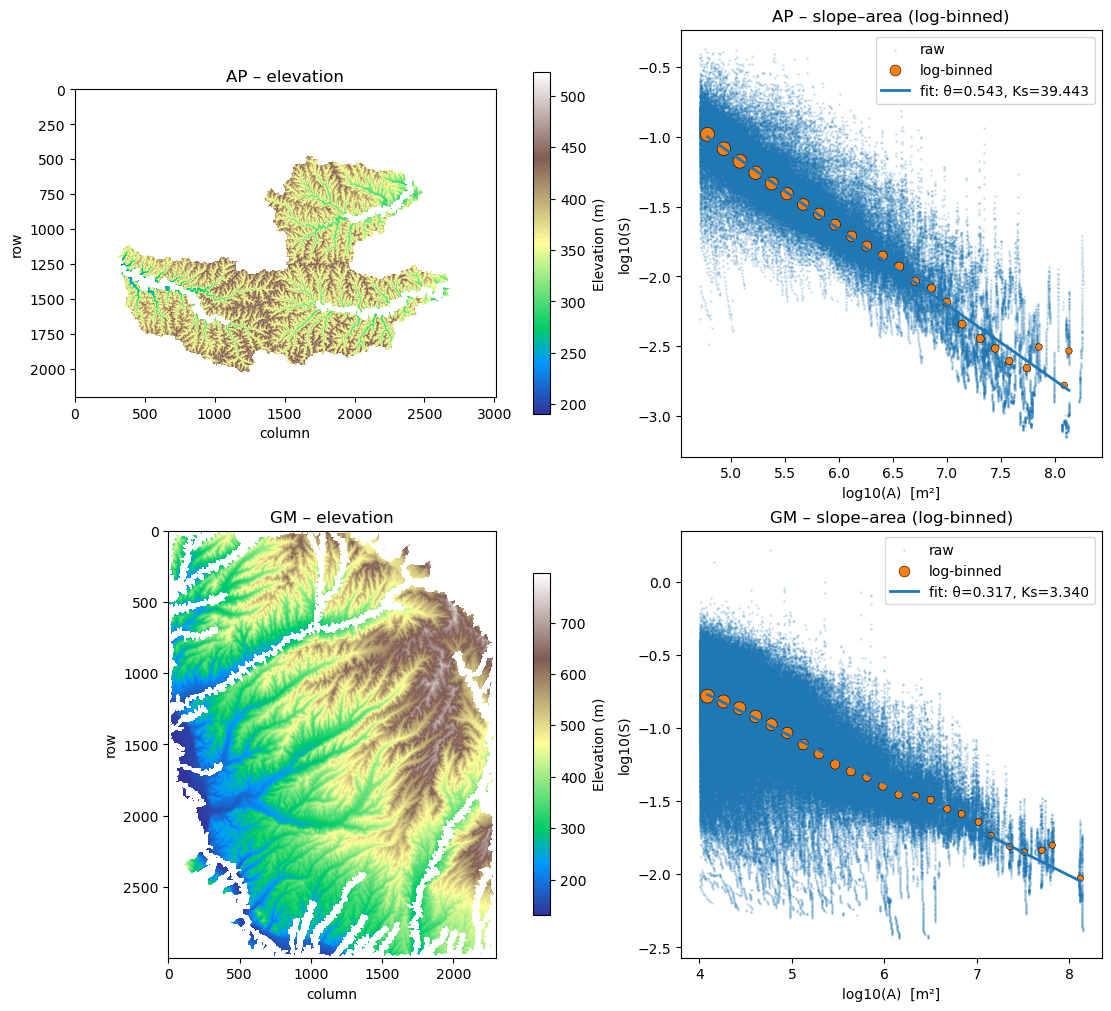

In [14]:
# ===============================================
# Slope–Area concavity (θ) and steepness (Ks) via log-binned regression
# Works with AP / GM datasets defined in DATA (filled elev, area, fd)
# ===============================================
import numpy as np
import matplotlib.pyplot as plt
from TopoAnalysis import dem as d

# -----------------------
# 0) Dataset registry (from your χ code)
# -----------------------
DATA = {
    "AP": dict(
        elev="data/taylors_original_dataset/AP_filled",
        area="data/taylors_original_dataset/AP_area",
        flow="data/taylors_original_dataset/AP_fd",
        A_MIN=5.04e4,  # channel threshold (m^2)
    ),
    "GM": dict(
        elev="data/taylors_original_dataset/GM_10mN_filled",
        area="data/taylors_original_dataset/GM_10mN_area",
        flow="data/taylors_original_dataset/GM_10mN_fd",
        A_MIN=1.0e4,   # channel threshold (m^2)
    ),
}

# -----------------------
# 1) Helpers
# -----------------------
def _load_elevation(path):
    """Try Elevation first, fall back to FilledElevation."""
    try:
        return d.Elevation.load(path)
    except Exception:
        return d.FilledElevation.load(path)

def slope_area_regression_binned(
    elev_obj, area_obj, fd_obj, min_area,
    vertical_interval=10.0, nbins=24, min_per_bin=10,
    agg="median", relax_if_sparse=True
):
    """
    Fit log10(S) vs log10(A) using log-binned aggregates → (Ks, theta, dbg).
    Slope is computed along channels using TopoAnalysis smoothing.
    """
    slope_obj = d.ChannelSlopeWithSmoothing(
        elevation=elev_obj, area=area_obj, flow_direction=fd_obj,
        vertical_interval=vertical_interval, min_area=min_area
    )
    S = slope_obj._griddata.flatten()
    A = area_obj._griddata.flatten()
    m = (A >= float(min_area)) & (S > 0) & np.isfinite(A) & np.isfinite(S)

    if np.count_nonzero(m) < 30:
        raise ValueError(f"Insufficient channel pixels after mask: {np.count_nonzero(m)}")

    logA = np.log10(A[m]); logS = np.log10(S[m])
    a_min, a_max = float(np.min(logA)), float(np.max(logA))
    if not np.isfinite(a_min) or a_min == a_max:
        raise ValueError("Degenerate log10(A) range for binning.")
    edges = np.linspace(a_min, a_max, nbins + 1)

    def _agg(min_required):
        outA, outS, outN = [], [], []
        for i in range(nbins):
            L, R = edges[i], edges[i+1]
            idx = (logA >= L) & (logA < R) if i < nbins - 1 else (logA >= L) & (logA <= R)
            c = int(np.count_nonzero(idx))
            if c < min_required:
                continue
            if agg == "median":
                a_val = float(np.median(logA[idx]))
                s_val = float(np.median(logS[idx]))
            else:
                a_val = float(np.mean(logA[idx]))
                s_val = float(np.mean(logS[idx]))
            outA.append(a_val); outS.append(s_val); outN.append(c)
        return np.asarray(outA), np.asarray(outS), np.asarray(outN, float)

    bA, bS, w = _agg(min_per_bin)
    if relax_if_sparse and (bA.size < 3):
        for target in [max(3, min_per_bin // 2), 3]:
            bA, bS, w = _agg(target)
            if bA.size >= 3:
                break
    if bA.size < 3:
        raise ValueError("Too few populated bins for regression.")

    # weighted least squares on binned points
    wx = np.sum(w * bA) / np.sum(w); wy = np.sum(w * bS) / np.sum(w)
    num = np.sum(w * (bA - wx) * (bS - wy))
    den = np.sum(w * (bA - wx)**2)
    if den <= 0:
        raise RuntimeError("Zero variance in binned log10(A).")
    b1 = num / den
    b0 = wy - b1 * wx

    Ks    = 10.0**b0
    theta = -b1

    dbg = dict(logA=logA, logS=logS, bin_logA=bA, bin_logS=bS, bin_counts=w, bin_edges=edges)
    return Ks, theta, dbg

# -----------------------
# 2) Run for each dataset
# -----------------------
tiles = DATA  # keep your old naming
nrows = len(tiles)
fig, axes = plt.subplots(nrows, 2, figsize=(11, 5*nrows), constrained_layout=True)
if nrows == 1:
    axes = np.array([axes])  # ensure 2D axes array

for row, (tag, cfg) in enumerate(tiles.items()):
    elev = _load_elevation(cfg["elev"])
    area = d.Area.load(cfg["area"])
    fd   = d.FlowDirectionD8.load(cfg["flow"])

    # ---- elevation plot
    ax_e = axes[row, 0]
    im = ax_e.imshow(elev._griddata, cmap="terrain", origin="upper")
    ax_e.set_title(f"{tag} – elevation")
    ax_e.set_xlabel("column"); ax_e.set_ylabel("row")
    fig.colorbar(im, ax=ax_e, shrink=0.8, label="Elevation (m)")

    # ---- slope–area (log-binned) regression
    Ks, theta, dbg = slope_area_regression_binned(
        elev_obj=elev, area_obj=area, fd_obj=fd,
        min_area=cfg["A_MIN"],
        vertical_interval=10.0,   # matches your 30 m workflow smoothing
        nbins=24, min_per_bin=10, agg="median",
        relax_if_sparse=True
    )

    # ---- slope–area plot: raw + binned + fit
    ax_sa = axes[row, 1]
    logA_raw, logS_raw = dbg["logA"], dbg["logS"]
    ax_sa.scatter(logA_raw, logS_raw, s=1, alpha=0.15, label="raw")

    bA, bS, bN = dbg["bin_logA"], dbg["bin_logS"], dbg["bin_counts"]
    size = 20 + 80 * (bN / bN.max()) if bN.size and bN.max() > 0 else 40
    ax_sa.scatter(bA, bS, s=size, edgecolor="k", linewidths=0.4, label="log-binned")

    x_fit = np.linspace(bA.min(), bA.max(), 200)
    ax_sa.plot(x_fit, np.log10(Ks) - theta * x_fit, lw=2,
               label=f"fit: θ={theta:.3f}, Ks={Ks:.3f}")

    ax_sa.set_xlabel("log10(A)  [m²]")
    ax_sa.set_ylabel("log10(S)")
    ax_sa.set_title(f"{tag} – slope–area (log-binned)")
    ax_sa.legend(loc="best", frameon=True)

    print(f"{tag}: concavity θ = {theta:.3f}   steepness Ks = {Ks:.3f}")

plt.show()
